# Blood Cell Detection — YOLOv3 from Scratch & Architecture Experiments

**Object Detection · PyTorch · YOLOv3 · CSP-Darknet · PAN-FPN · CIoU · Focal Loss**

## Актуальность и постановка задачи

Автоматическая локализация клеток крови на микроскопических изображениях — прикладная задача компьютерного зрения. Детектор должен находить объекты разного размера, корректно классифицировать их и ограничивать число ложных срабатываний.

**Цель:** реализовать детектор семейства YOLO на PyTorch и исследовать влияние backbone, neck и функции потерь на качество детекции клеток крови.

**Данные:** [Blood Cell Detection Dataset (Kaggle)](https://www.kaggle.com/datasets/adhoppin/blood-cell-detection-datatset/data). Классы: WBC (лейкоциты), RBC (эритроциты), Platelets (тромбоциты). Используются исходные разбиения train/valid/test.

## Реализация from scratch

В ноутбуке непосредственно реализованы на **PyTorch** архитектура YOLOv3 с Darknet-53, компоненты CSP-Darknet (Conv, Bottleneck, C2f, SPPF), PAN-FPN neck, а также компоненты функций потерь, декодирование предсказаний, NMS, подбор порогов и цикл экспериментов. Это реализация архитектурных компонентов, а не использование готового детектора из Ultralytics.

## Экспериментальный дизайн

1. Базовый YOLOv3 / Darknet-53.
2. YOLOv3 с CSP-Darknet backbone.
3. CSP-Darknet + PAN-FPN.
4. CSP-Darknet + PAN-FPN + CIoU / Focal loss.

**Основная метрика:** mAP@0.50:0.95. **Дополнительные:** mAP@0.50, mAP@0.75, среднее время инференса на изображение. Пороги confidence и NMS IoU выбираются на validation, качество оценивается на test.

## Результаты на тестовой выборке

| Конфигурация | mAP@0.50:0.95 | mAP@0.50 | mAP@0.75 | Инференс, мс/изображение |
|---|---:|---:|---:|---:|
| YOLOv3 / Darknet-53 | 0.1668 | 0.5834 | 0.0316 | 68.46 |
| + CSP-Darknet | 0.2208 | 0.5993 | 0.0472 | 238.72 |
| + PAN-FPN | 0.1582 | 0.4896 | 0.0415 | 680.06 |
| + CIoU / Focal loss | **0.4302** | **0.8053** | **0.4588** | **36.33** |

Значения взяты из сохранённых выводов экспериментов. Далее приведены реализация и визуализация результатов.


In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

In [2]:
import os, time, random, math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from sklearn.cluster import KMeans

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from typing import Any, Tuple, List, Optional, Union, Callable
from torch.optim import Optimizer
from sklearn.model_selection import train_test_split
from torchmetrics.detection.mean_ap import MeanAveragePrecision
import time
from typing import Dict, Any, Optional
import pandas as pd

SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Torch:", torch.__version__, "| Device:", device)

torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

BATCH_SIZE = 8


Torch: 2.7.1+cu126 | Device: cuda


## 1. Контекст исследования

YOLOv3 — одностадийный детектор, формирующий предсказания на нескольких масштабах. В проекте исследуется последовательная модернизация его архитектурных компонентов.

## 2. Данные и подготовка эксперимента

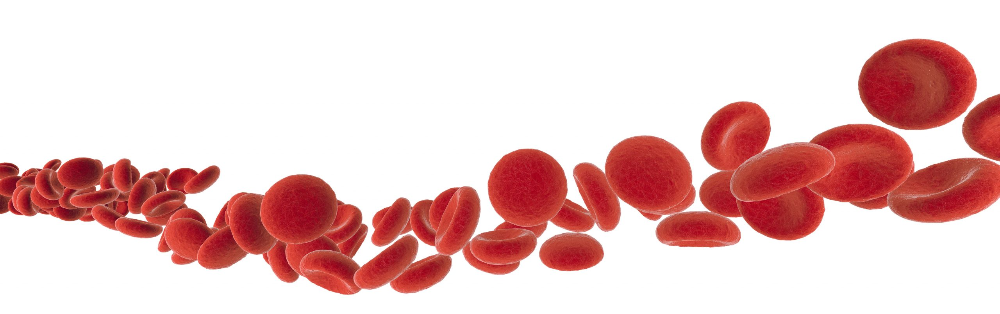

Датасет содержит микроскопические изображения и bounding boxes для трёх классов клеток крови: **WBC**, **RBC** и **Platelets**. Используются исходные разбиения train, validation и test.

### PyTorch Dataset

In [3]:
class BloodCellDataset(Dataset):
    """
    PyTorch-датасет для BloodCell Detection Dataset в cx-cy-w-h формате.

    Ожидаемая структура:
        root_dir/
          train|valid|test/
            images/*.jpg
            labels/*.txt  (label cx cy w h, координаты нормализованы [0,1])

    Предполагается, что все изображения уже приведены к одному размеру (416×416).

    На выходе:
        image : Tensor (3, H, W)
        target: dict с полями
            "boxes"  — Tensor (N,4) в cxcxwh-формате,
            "labels" — Tensor (N,) с индексами классов,
            "path"   — путь до исходного файла.
    """

    def __init__(self, root_dir: str | Path, split: str = "train"):
        """Инициализирует датасет, находя пути ко всем изображениям.

        Args:
            root_dir (str | Path): Путь к корневой директории датасета.
            split (str, optional): Сплит данных ("train", "valid", "test").
                По умолчанию "train".
        """
        assert split in ["train", "valid", "test"]
        split_dir = Path(root_dir) / split
        self.img_dir = split_dir / "images"
        self.label_dir = split_dir / "labels"

        exts = {".jpg", ".jpeg", ".png"}
        self.img_paths = sorted([p for p in self.img_dir.rglob("*") if p.suffix.lower() in exts])

    def __len__(self) -> int:
        """Возвращает общее количество изображений в датасете."""
        return len(self.img_paths)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, dict]:
        """Загружает и возвращает один элемент датасета по индексу.

        Args:
            idx (int): Индекс запрашиваемого элемента.

        Returns:
            tuple[torch.Tensor, dict]: Кортеж (image, target), где:
                - image: тензор изображения (C, H, W).
                - target: словарь с аннотациями {"boxes", "labels", "path"}.
        """
        ip = self.img_paths[idx]
        lbl = self.label_dir / (ip.stem + ".txt")

        # Считываем изображение
        img = Image.open(ip).convert("RGB")

        # Считываем координаты боксов и классы
        boxes = []
        labels = []
        if lbl.exists():
            with open(lbl, "r") as f:
                for line in f.read().strip().splitlines():
                    vals = line.strip().split()
                    if len(vals) >= 5:
                        labels.append(int(float(vals[0])))
                        cx, cy, w, h = map(float, vals[1:5])
                        boxes.append([cx, cy, w, h])

        img_t = transforms.ToTensor()(img)
        boxes = torch.tensor(boxes, dtype=torch.float32)
        labels = torch.tensor(labels, dtype=torch.int64)

        target = {"boxes": boxes, "labels": labels, "path": str(ip)}
        return img_t, target

### Формирование батчей

In [4]:
def collate_fn(batch):
    """
    Эта функция поясняет DataLoader как комбинировать данные в батч.
    Для этого мы будем использовать списки.
    Аргумент:
      batch: итерируемый объект из __getitem__()
    Возвращает:
      тензор картинок, список тензоров боксов, список тензоров лейблов
    """
    images = []
    boxes = []
    labels = []

    for b in batch:
        images.append(b[0])
        boxes.append(b[1]["boxes"])
        labels.append(b[1]["labels"])

    images = torch.stack(images)

    return images, boxes, labels

### Загрузка train / validation / test

In [5]:
DATA_ROOT = Path("/home/eidlin/kag/data/")

train_dataset = BloodCellDataset(DATA_ROOT, split="train")
val_dataset = BloodCellDataset(DATA_ROOT, split="valid")
test_dataset = BloodCellDataset(DATA_ROOT, split="test")

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn
)

print(
    f"Dataset sizes — train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}"
)


Dataset sizes — train: 765, val: 73, test: 36


In [6]:
IMG_SIZE = 416  # Размер квадратного изображения
NUM_CLASSES = 3  # Кол-во классов
CLASS_NAMES: list[str] = [
    "WBC",  # class 0 лейкоциты
    "RBC",  # class 1 эритроциты
    "Platelets",  # class 2 тромбоциты
]

Собрано 10336 боксов для k-means кластеризации.
Рассчитанные анкеры (пиксели, масштаб 416x416):
P3 (мелкие): [[32.0, 31.0], [65.0, 76.0], [85.0, 63.0]]
P4 (средние): [[55.0, 98.0], [78.0, 98.0], [102.0, 76.0]]
P5 (крупные): [[128.0, 128.0], [147.0, 186.0], [192.0, 153.0]]


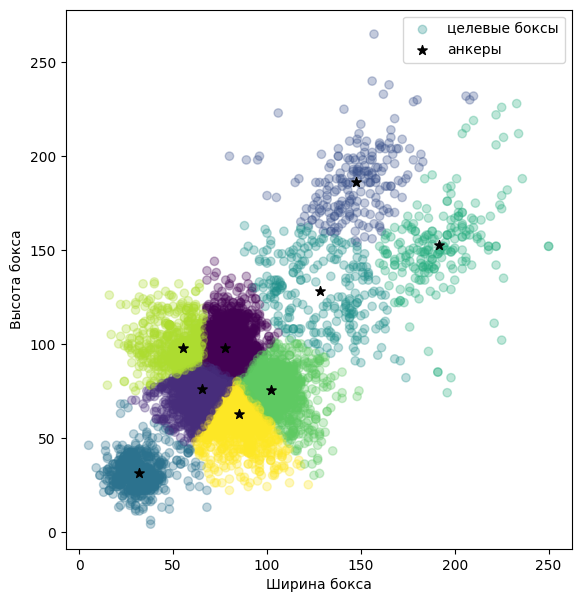

In [7]:
def calculate_anchors(
    dataset,
    num_anchors=9,
    input_size=416
):
    """
    Вычисляет оптимальные якоря для YOLOv3, используя k-means
    по всем боксам из датасета (split='train').

    На входе:
        dataset: экземпляр BloodCellDataset (train)
                 __getitem__ -> (image, target),
                 target["boxes"] в формате cx, cy, w, h, нормализовано [0,1].

    Анкеры будут посчитаны в пикселях относительно фактического размера
    картинок (берём H,W из image.shape).
    """

    all_scaled_boxes_wh = []

    for img, target in dataset:
        boxes = target["boxes"]  # (N, 4) cxc ywh, нормализованы [0,1]
        if boxes.numel() == 0:
            continue

        # Размер картинки
        _, H, W = img.shape

        # w,h в пикселях
        widths = boxes[:, 2] * W
        heights = boxes[:, 3] * H

        # фильтруем нулевые/отрицательные боксы
        mask = (widths > 0) & (heights > 0)
        if mask.sum() == 0:
            continue

        wh = torch.stack([widths[mask], heights[mask]], dim=1)  # (M, 2)
        all_scaled_boxes_wh.append(wh)


    if not all_scaled_boxes_wh:
        print("Не найдено ни одного бокса. Невозможно рассчитать анкеры.")
        return None

    # --- K-Means ---
    all_scaled_boxes_wh = torch.cat(all_scaled_boxes_wh, dim=0).cpu().numpy()
    print(f"Собрано {len(all_scaled_boxes_wh)} боксов для k-means кластеризации.")

    kmeans = KMeans(n_clusters=num_anchors, random_state=42, n_init=10)
    anchors_lables = kmeans.fit_predict(all_scaled_boxes_wh)

    # Центроиды - это и есть наши анкеры [w, h] в пикселях (масштаб 416)
    anchors_pixels = kmeans.cluster_centers_

    # Визуализация кластеров
    plt.figure(figsize=(7, 7))
    plt.scatter(all_scaled_boxes_wh[:, 0], all_scaled_boxes_wh[:, 1], c=anchors_lables, alpha=0.3, label='целевые боксы')
    plt.scatter(anchors_pixels[:, 0], anchors_pixels[:, 1], c="black", marker='*', label='анкеры', s=50)
    plt.xlabel('Ширина бокса')
    plt.ylabel('Высота бокса')
    plt.legend()
    plt.gca().set_aspect(1.)

    # 1. Сортируем по площади (от меньшего к большему)
    areas = anchors_pixels[:, 0] * anchors_pixels[:, 1]
    sorted_indices = np.argsort(areas)
    anchors_sorted = anchors_pixels[sorted_indices]

    # 2. Округляем и разбиваем на 3 группы (P3, P4, P5)
    anchors_pixels_rounded = np.round(anchors_sorted).tolist()

    anchors_p3 = torch.tensor(anchors_pixels_rounded[0:3]) # мелкие
    anchors_p4 = torch.tensor(anchors_pixels_rounded[3:6]) # средние
    anchors_p5 = torch.tensor(anchors_pixels_rounded[6:9]) # крупные

    print("Рассчитанные анкеры (пиксели, масштаб 416x416):")
    print(f"P3 (мелкие): {anchors_p3.tolist()}")
    print(f"P4 (средние): {anchors_p4.tolist()}")
    print(f"P5 (крупные): {anchors_p5.tolist()}")

    # Возвращаем в том порядке, который ожидает YoloLoss (P5, P4, P3)
    return [anchors_p5, anchors_p4, anchors_p3]


anchors = calculate_anchors(train_dataset)


### Преобразование координат bounding boxes

In [8]:
def cxcywh_to_x1y1x2y2(cx, cy, w, h):
    """Конвертирует координаты прямоугольника из формата (центр, размеры) в (углы).

    Args:
        cx (float): Нормализованная координата X центра прямоугольника.
        cy (float): Нормализованная координата Y центра прямоугольника.
        w (float): Нормализованная ширина прямоугольника.
        h (float): Нормализованная высота прямоугольника.

    Returns:
        tuple[float, float, float, float]: Кортеж с абсолютными пиксельными
            координатами (xmin, ymin, xmax, ymax), где (xmin, ymin) — это
            верхний левый угол, а (xmax, ymax) — нижний правый.
    """
    xmin, xmax = (cx - w / 2) * IMG_SIZE, (cx + w / 2) * IMG_SIZE
    ymin, ymax = (cy - h / 2) * IMG_SIZE, (cy + h / 2) * IMG_SIZE
    return xmin, ymin, xmax, ymax

### Визуализация размеченных объектов

In [9]:
CLASS_COLORS: list[str] = [
    "white",  # class 0
    "red",  # class 1
    "cyan",  # class 2
]


def draw_img_boxes(
    img_t: torch.Tensor,
    boxes: Union["np.ndarray", torch.Tensor],
    labels: Optional[Union["np.ndarray", torch.Tensor]] = None,
    scores: Optional[Union["np.ndarray", torch.Tensor]] = None,
) -> "Image.Image":
    """
    Рисует прямоугольники (bounding boxes) цветом в зависимости от класса.

    Args:
        img_t: Изображение в формате тензора формы (C, H, W).
        boxes: Массив или тензор боксов формы (N, 4) в формате xyxy.
        labels: Необязательный массив или тензор меток классов формы (N,).
            Если не указан, используется цвет по умолчанию.
        scores: Необязательный массив или тензор confidence-оценок формы (N,).
            Если указан, значение выводится рядом с меткой класса.

    Returns:
        PIL-изображение с нарисованными bounding boxes.
    """
    # Преобразуем тензор в PIL изображение
    img = transforms.ToPILImage()(img_t.cpu()).convert("RGB")

    # Создаем контекст для рисования на изображении
    draw = ImageDraw.Draw(img)

    # Преобразуем таргет в numpy формат
    if isinstance(boxes, torch.Tensor):
        boxes = boxes.cpu().numpy()
    if labels is not None and isinstance(labels, torch.Tensor):
        labels = labels.cpu().numpy()
    if scores is not None and isinstance(scores, torch.Tensor):
        scores = scores.cpu().numpy()

    # Рисуем боксы с подписями
    n = len(boxes)
    for i in range(n):
        cx, cy, w, h = [float(x) for x in boxes[i]]
        x1, y1, x2, y2 = cxcywh_to_x1y1x2y2(cx, cy, w, h)
        c_id = int(labels[i]) if labels is not None and i < len(labels) else 0
        c_name = CLASS_NAMES[c_id]
        color = CLASS_COLORS[c_id % len(CLASS_COLORS)]
        # Рисуем боксы
        draw.rectangle([x1, y1, x2, y2], outline=color, width=2)
        if labels is not None:
            txt = str(c_name)
            # Также можно показать уверенность предсказания
            if scores is not None and i < len(scores):
                txt += f" p={scores[i]:.2f}"
            # К боксам добавляем текст
            draw.text((x1 + 2, y1 + 2), txt, fill=color)
    return img

### Примеры изображений и разметки

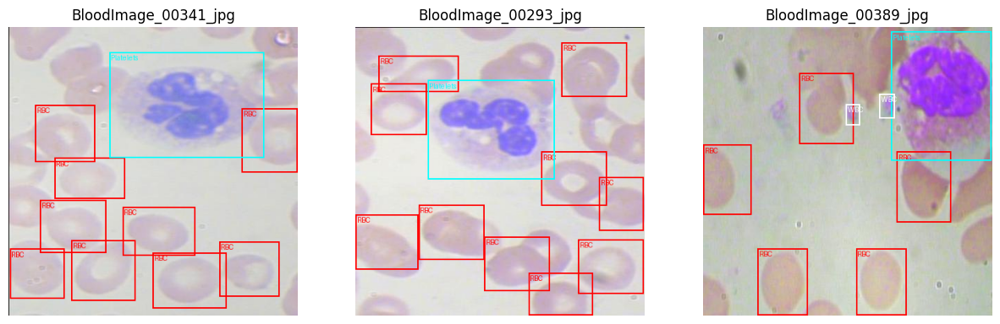

In [10]:
num_examples = 3
fig, axes = plt.subplots(1, num_examples, figsize=(5 * num_examples, 5))
if num_examples == 1:
    axes = [axes]
sample_idxs = random.sample(range(len(train_dataset)), k=min(num_examples, len(train_dataset)))
for ax, idx in zip(axes, sample_idxs):
    img_t, target = train_dataset[idx]
    boxes, labels = target["boxes"], target["labels"]
    img_drawn = draw_img_boxes(img_t, boxes, labels)
    ax.imshow(img_drawn)
    ax.set_title(Path(target["path"]).name.split(".")[0])
    ax.axis("off")
plt.show()


## 3. Базовая модель YOLOv3 from scratch

Реализация backbone Darknet-53, detection heads, функций потерь, подготовки targets и inference pipeline. Размеры anchors рассчитываются методом K-means по обучающей выборке. После обучения подбираются confidence/NMS thresholds на validation и оценивается качество на test.

In [11]:
class CNNBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride, padding=None):
        super(CNNBlock, self).__init__()

        if padding is None:
            padding = kernel_size // 2

        self.conv = nn.Conv2d(
            in_channels, out_channels,
            kernel_size, stride, padding, bias=False
        )
        self.bn = nn.BatchNorm2d(out_channels)
        self.activation = nn.LeakyReLU(0.1, inplace=True)

    def forward(self, x):
        return self.activation(self.bn(self.conv(x)))


class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super(ResidualBlock, self).__init__()
        self.block = nn.Sequential(
            CNNBlock(channels, channels // 2, kernel_size=1, stride=1),
            CNNBlock(channels // 2, channels, kernel_size=3, stride=1),
        )

    def forward(self, x):
        return x + self.block(x)


class Darknet53(nn.Module):
    def __init__(self):
        super().__init__()

        self._make_residual_layer = lambda c, n: nn.Sequential(
            *[ResidualBlock(c) for _ in range(n)]
        )

        self.conv_in = CNNBlock(3, 32, kernel_size=3, stride=1)

        self.stage1 = nn.Sequential(
            CNNBlock(32, 64, 3, 2),
            self._make_residual_layer(64, 1),
        )
        self.stage2 = nn.Sequential(
            CNNBlock(64, 128, 3, 2),
            self._make_residual_layer(128, 2),
        )
        self.stage3 = nn.Sequential(
            CNNBlock(128, 256, 3, 2),
            self._make_residual_layer(256, 8),
        )
        self.stage4 = nn.Sequential(
            CNNBlock(256, 512, 3, 2),
            self._make_residual_layer(512, 8),
        )
        self.stage5 = nn.Sequential(
            CNNBlock(512, 1024, 3, 2),
            self._make_residual_layer(1024, 4),
        )

    def forward(self, x):
        x = self.conv_in(x)
        x = self.stage1(x)
        x = self.stage2(x)
        p3 = self.stage3(x)
        p4 = self.stage4(p3)
        p5 = self.stage5(p4)
        return p3, p4, p5


class YOLONeck_FPN(nn.Module):
    def __init__(self):
        super().__init__()

        self._make_neck = lambda in_c, out_c: nn.Sequential(
            CNNBlock(in_c, out_c, 1, 1),
            CNNBlock(out_c, out_c * 2, 3, 1),
            CNNBlock(out_c * 2, out_c, 1, 1),
            CNNBlock(out_c, out_c * 2, 3, 1),
            CNNBlock(out_c * 2, out_c, 1, 1),
        )

        self._upsample = lambda in_c, out_c: nn.Sequential(
            CNNBlock(in_c, out_c, 1, 1),
            nn.Upsample(scale_factor=2, mode="nearest"),
        )

        self.neck_p5 = self._make_neck(1024, 512)
        self.upsample_p5_to_p4 = self._upsample(512, 256)
        self.neck_p4 = self._make_neck(768, 256)
        self.upsample_p4_to_p3 = self._upsample(256, 128)
        self.neck_p3 = self._make_neck(384, 128)

    def forward(self, p3_in, p4_in, p5_in):
        features_p5 = self.neck_p5(p5_in)
        upsampled_p5 = self.upsample_p5_to_p4(features_p5)

        combined_p4 = torch.cat([upsampled_p5, p4_in], dim=1)
        features_p4 = self.neck_p4(combined_p4)
        upsampled_p4 = self.upsample_p4_to_p3(features_p4)

        combined_p3 = torch.cat([upsampled_p4, p3_in], dim=1)
        features_p3 = self.neck_p3(combined_p3)

        return features_p3, features_p4, features_p5


class PredictionHead(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.head = nn.Sequential(
            CNNBlock(in_channels, in_channels * 2, kernel_size=3, stride=1),
            nn.Conv2d(
                in_channels * 2,
                out_channels,
                kernel_size=1,
                stride=1,
                padding=0,
                bias=True,
            ),
        )

    def forward(self, x):
        return self.head(x)


class YOLOHeads(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        out_ch = 3 * (5 + num_classes)
        self.head_p3 = PredictionHead(in_channels=128, out_channels=out_ch)
        self.head_p4 = PredictionHead(in_channels=256, out_channels=out_ch)
        self.head_p5 = PredictionHead(in_channels=512, out_channels=out_ch)

    def forward(self, n3, n4, n5):
        out_p3 = self.head_p3(n3)
        out_p4 = self.head_p4(n4)
        out_p5 = self.head_p5(n5)
        return out_p3, out_p4, out_p5


class YOLOv3(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.backbone = Darknet53()
        self.neck = YOLONeck_FPN()
        self.head = YOLOHeads(num_classes=num_classes)
        self.num_classes = num_classes
        self.num_anchors = 3

    def _format_output(self, tensor):
        B, C, H, W = tensor.shape
        tensor = tensor.view(B, self.num_anchors, -1, H, W)
        tensor = tensor.permute(0, 3, 4, 1, 2).contiguous()
        return tensor

    def forward(self, x):
        p3, p4, p5 = self.backbone(x)
        n3, n4, n5 = self.neck(p3, p4, p5)
        raw_out_p3, raw_out_p4, raw_out_p5 = self.head(n3, n4, n5)
        out_p3 = self._format_output(raw_out_p3)
        out_p4 = self._format_output(raw_out_p4)
        out_p5 = self._format_output(raw_out_p5)
        # порядок [P5, P4, P3], как ожидает твой тренировочный код
        return [out_p5, out_p4, out_p3]


In [12]:
class BoxLoss(nn.Module):
    """Штрафует за ошибки в предсказании координат бокса"""
    def __init__(self):
        super().__init__()
        self.mse = nn.MSELoss()

    def forward(self, pred_box, target_box, obj_mask):
        if not obj_mask.any():
            return 0.0

        # Loss для координат центра бокса
        loss_box_xy = self.mse(pred_box[..., 0:2][obj_mask], target_box[..., 0:2][obj_mask])

        # Loss для ширины и высоты бокса
        loss_box_wh = self.mse(pred_box[..., 2:4][obj_mask], target_box[..., 2:4][obj_mask])

        return loss_box_xy + loss_box_wh

class ObjectnessLoss(nn.Module):
    """Штрафует за ошибки в предсказании наличия/отсутствия объекта"""
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, pred_obj, target_obj, obj_mask, noobj_mask):
        loss_obj = self.bce(pred_obj[obj_mask], target_obj[obj_mask]) if obj_mask.any() else 0.0
        loss_noobj = self.bce(pred_obj[noobj_mask], target_obj[noobj_mask]) if noobj_mask.any() else 0.0
        return loss_obj, loss_noobj

class ClassLoss(nn.Module):
    """Штрафует за ошибки в предсказании класса объекта"""
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, pred_class, target_class, obj_mask):
        if not obj_mask.any():
            return 0.0
        loss_class = self.bce(pred_class[obj_mask], target_class[obj_mask])
        return loss_class

def bbox_iou(box1, box2, x1y1x2y2=True):
    """
    Вычисляет IOU для 2х боксов
    """
    if not x1y1x2y2:
        # Переводим из координат центра и ширины в формат x1y1x2y2
        b1_x1, b1_x2 = box1[:, 0] - box1[:, 2] / 2, box1[:, 0] + box1[:, 2] / 2
        b1_y1, b1_y2 = box1[:, 1] - box1[:, 3] / 2, box1[:, 1] + box1[:, 3] / 2
        b2_x1, b2_x2 = box2[:, 0] - box2[:, 2] / 2, box2[:, 0] + box2[:, 2] / 2
        b2_y1, b2_y2 = box2[:, 1] - box2[:, 3] / 2, box2[:, 1] + box2[:, 3] / 2
    else:
        # Получаем координаты боксов
        b1_x1, b1_y1, b1_x2, b1_y2 = box1[:, 0], box1[:, 1], box1[:, 2], box1[:, 3]
        b2_x1, b2_y1, b2_x2, b2_y2 = box2[:, 0], box2[:, 1], box2[:, 2], box2[:, 3]

    # Считаем координаты квадрата пересечения
    inter_rect_x1 = torch.max(b1_x1, b2_x1)
    inter_rect_y1 = torch.max(b1_y1, b2_y1)
    inter_rect_x2 = torch.min(b1_x2, b2_x2)
    inter_rect_y2 = torch.min(b1_y2, b2_y2)

    # Площадь пересечения
    inter_area = torch.clamp(inter_rect_x2 - inter_rect_x1 + 1, min=0) * torch.clamp(
        inter_rect_y2 - inter_rect_y1 + 1, min=0
    )

    # Площади первого и второго боксов
    b1_area = (b1_x2 - b1_x1 + 1) * (b1_y2 - b1_y1 + 1)
    b2_area = (b2_x2 - b2_x1 + 1) * (b2_y2 - b2_y1 + 1)

    # IoU
    iou = inter_area / (b1_area + b2_area - inter_area + 1e-16)

    return iou


class TargetBuilder(nn.Module):
    def __init__(self, anchors_by_scale, num_classes=7, ignore_thresh=0.5):
        """
        Инициализирует TargetBuilder для создания целевых меток YOLO.

        Args:
            anchors_by_scale (list of torch.Tensor): Список тензоров, где каждый тензор содержит якоря [width, height]
                                                   для соответствующего масштаба (P5, P4, P3).
            num_classes (int, optional): Количество классов для обнаружения. По умолчанию 7.
            ignore_thresh (float, optional): IoU-порог, выше которого предсказания считаются 'игнорируемыми'
                                           для расчета objectness loss. По умолчанию 0.5.
        """
        super().__init__()
        self.num_classes = num_classes
        self.ignore_thresh = ignore_thresh

        # self.anchors - это анкеры в ПИКСЕЛЯХ (e.g., [116, 90])
        self.anchors = anchors_by_scale
        self.num_anchors = 3

        # Размеры сеток
        self.grid_sizes = [13, 26, 52]
        # Страйды для 416x416.
        # (416/13=32, 416/26=16, 416/52=8)
        self.strides = [32, 16, 8]
        # Масштабированные анкеры.
        # Мы делим пиксельные анкеры на страйд, чтобы получить
        # анкеры в "сеточных" единицах (grid units)
        self.anchors_grid_units = [
            anchors.float() / stride
            for anchors, stride in zip(self.anchors, self.strides)
        ]


    def forward(self, predictions, targets):
        """
        Создает целевые тензоры для YOLO-Loss.

        Args:
            predictions (list of torch.Tensor): Список предсказаний модели для каждого масштаба (P5, P4, P3).
                                              Каждый тензор имеет форму (B, S, S, num_anchors, 5 + num_classes).
            targets (torch.Tensor): Тензор истинных меток (Ground Truth) объектов в батче.
                                    Формат: (N, 6), где N - общее количество объектов в батче,
                                    а 6 включает [batch_idx, class_id, cx, cy, w, h] (нормализованные).

        Returns:
            tuple: Кортеж из трех списков:
                - all_obj_masks (list of torch.Tensor): Маски, указывающие, какие якоря соответствуют объектам.
                - all_noobj_masks (list of torch.Tensor): Маски, указывающие, какие якоря не соответствуют объектам
                                                        и не игнорируются.
                - all_target_tensors (list of torch.Tensor): Целевые тензоры для каждой головы YOLO.
                                                           Формат: (B, S, S, num_anchors, 5 + num_classes).
        """
        all_obj_masks = []
        all_noobj_masks = []
        all_target_tensors = []

        # (predictions идет в порядке P5, P4, P3,
        # поэтому grid_sizes и anchors должны быть в том же порядке)
        for scale_idx, p in enumerate(predictions):
            B, S, _, A, _ = p.shape # S = 13, 26, или 52 (grid_size)

            obj_mask = torch.zeros((B, S, S, A), dtype=torch.bool, device=p.device)
            noobj_mask = torch.ones((B, S, S, A), dtype=torch.bool, device=p.device)
            target_box_coords = torch.zeros((B, S, S, A, 4), device=p.device)
            target_obj_conf = torch.zeros((B, S, S, A, 1), device=p.device)
            target_class_probs = torch.zeros((B, S, S, A, self.num_classes), device=p.device)

            # Берем анкеры, УЖЕ сконвертированные в "сеточные" единицы
            current_anchors_grid = self.anchors_grid_units[scale_idx].to(p.device)

            for t in targets:
                batch_idx, t_class, t_x, t_y, t_w, t_h = t
                batch_idx = int(batch_idx)

                # --- Приводим GT к "сеточным" единицам ---
                # (t_x, t_y, t_w, t_h) - нормализованные (0-1)

                # Координаты центра в "сеточных" единицах
                t_x_grid = t_x * S
                t_y_grid = t_y * S
                # Ширина и высота в "сеточных" единицах
                t_w_grid = t_w * S
                t_h_grid = t_h * S

                # Индексы ячейки (i, j)
                j, i = int(t_x_grid), int(t_y_grid)
                if i >= S or j >= S:
                    continue # пропустить, если бокс за пределами сетки

                # 1. GT бокс (в "сеточных" единицах)
                gt_box_grid = torch.tensor([0, 0, t_w_grid, t_h_grid], device=p.device).unsqueeze(0)

                # 2. Анкеры (в "сеточных" единицах)
                anchor_shapes_grid = torch.cat([
                    torch.zeros_like(current_anchors_grid),
                    current_anchors_grid
                ], dim=1)

                # 3. Считаем IoU
                ious = bbox_iou(gt_box_grid, anchor_shapes_grid, x1y1x2y2=False)

                # 4. Находим походящий анкер
                best_a = ious.argmax()

                # 5. Обновляем маски, указывающие, какие якоря соответствуют объектам,
                # и маски, указывающие, какие якоря не соответствуют объектам и не игнорируются.
                obj_mask[batch_idx, i, j, best_a] = 1
                noobj_mask[batch_idx, i, j, best_a] = 0
                noobj_mask[batch_idx, i, j, ious > self.ignore_thresh] = 0

                # 6. Считаем смещение центра таргета от центра ячейки
                target_box_coords[batch_idx, i, j, best_a, 0] = t_x_grid - j
                target_box_coords[batch_idx, i, j, best_a, 1] = t_y_grid - i

                # 7. Считаем отличия в масштабе размеров таргета от размеров анкера
                target_box_coords[batch_idx, i, j, best_a, 2] = torch.log(
                    t_w_grid / current_anchors_grid[best_a, 0] + 1e-16
                )
                target_box_coords[batch_idx, i, j, best_a, 3] = torch.log(
                    t_h_grid / current_anchors_grid[best_a, 1] + 1e-16
                )

                # 8. Также записываем конфиденс и вероятность для нужного анкера для нужного класса
                target_obj_conf[batch_idx, i, j, best_a] = 1.0
                target_class_probs[batch_idx, i, j, best_a, int(t_class)] = 1.0

            all_obj_masks.append(obj_mask)
            all_noobj_masks.append(noobj_mask)
            all_target_tensors.append(
                torch.cat([target_box_coords, target_obj_conf, target_class_probs], dim=-1)
            )

        return all_obj_masks, all_noobj_masks, all_target_tensors


class YoloLoss(nn.Module):
    def __init__(self, anchors_by_scale, num_classes=3, ignore_thresh=0.5):
        """
        Инициализирует функцию потерь YOLO (YoloLoss).

        Args:
            anchors_by_scale (list of torch.Tensor): Список тензоров, где каждый тензор содержит якоря [width, height]
                                                   для соответствующего масштаба (P5, P4, P3).
            num_classes (int, optional): Количество классов для обнаружения. По умолчанию 3.
            ignore_thresh (float, optional): IoU-порог для игнорирования предсказаний без объектов.
                                           По умолчанию 0.5.
        """
        super().__init__()
        self.target_builder = TargetBuilder(anchors_by_scale, num_classes, ignore_thresh)
        self.box_loss_fn = BoxLoss()
        self.obj_loss_fn = ObjectnessLoss()
        self.cls_loss_fn = ClassLoss()
        self.lambda_class = 1.0
        self.lambda_obj = 1.0
        self.lambda_noobj = 10.0
        self.lambda_box = 10.0

    def forward(self, predictions, targets):
        """
        Вычисляет общую функцию потерь YOLO для данного батча.

        Args:
            predictions (list of torch.Tensor): Список предсказаний модели для каждого масштаба (P5, P4, P3).
                                              Каждый тензор имеет форму (B, S, S, num_anchors, 5 + num_classes).
            targets (torch.Tensor): Тензор истинных меток (Ground Truth) объектов в батче.
                                    Формат: (N, 6), где N - общее количество объектов в батче,
                                    а 6 включает [batch_idx, class_id, cx, cy, w, h] (нормализованные).

        Returns:
            torch.Tensor: Общая функция потерь для батча.
        """
        # 1. Построение целевых тензоров (ground truth) для каждого масштаба
        # Это включает маски для объектов, отсутствия объектов и форматированные целевые данные
        obj_masks, noobj_masks, target_tensors = self.target_builder(predictions, targets)

        total_loss = 0
        # Получаем размер батча из первого предсказания
        B = predictions[0].shape[0]

        # 2. Итерация по каждому масштабу предсказаний (P5, P4, P3)
        for i, p in enumerate(predictions):
            # Разделение предсказаний на компоненты: координаты бокса, уверенность в объекте, вероятности классов
            pred_box = p[..., 0:4]      # (tx, ty, tw, th)
            pred_obj = p[..., 4:5]      # (to) objectness score
            pred_class = p[..., 5:]     # (c1, c2, ..., cn) class probabilities

            # Извлечение соответствующих целевых данных для текущего масштаба
            target_box = target_tensors[i][..., 0:4]
            target_obj = target_tensors[i][..., 4:5]
            target_class = target_tensors[i][..., 5:]

            # Извлечение масок для объектов и отсутствия объектов
            obj_mask = obj_masks[i]
            noobj_mask = noobj_masks[i]

            # 3. Вычисление отдельных компонентов лосс
            loss_box = self.box_loss_fn(pred_box, target_box, obj_mask)
            loss_obj, loss_noobj = self.obj_loss_fn(pred_obj, target_obj, obj_mask, noobj_mask)
            loss_class = self.cls_loss_fn(pred_class, target_class, obj_mask)

            # 4. Комбинирование компонентов лосса с весами
            # Эти веса (лямбды) позволяют настроить важность каждого типа ошибки
            scale_loss = (
                self.lambda_box * loss_box +
                self.lambda_obj * loss_obj +
                self.lambda_noobj * loss_noobj +
                self.lambda_class * loss_class
            )
            # Добавление лосса текущего масштаба к общему лоссу
            total_loss += scale_loss

        # 5. Нормализация общего лосса по размеру батча
        return total_loss / B

In [13]:
class AverageMeter:
    """Вычисляет и хранит среднее значения"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

def prepare_targets(boxes, labels, device):
    """Подготавливаем targets для YOLO loss"""
    targets = []
    for batch_idx, (batch_boxes, batch_labels) in enumerate(zip(boxes, labels)):
        for box, label in zip(batch_boxes, batch_labels):
            if len(box) == 4:  # cx, cy, w, h
                cx, cy, w, h = box
                targets.append([batch_idx, label, cx, cy, w, h])
    return torch.tensor(targets, device=device) if targets else torch.tensor([], device=device)

def train(train_loader, model, criterion, optimizer, history, epoch, n_epochs, device, print_freq=10):
    """Тренировка одной эпохи"""
    model.train()
    batch_time = AverageMeter()
    data_time = AverageMeter()
    losses = AverageMeter()
    start = time.time()

    for i, (images, boxes, labels) in enumerate(train_loader):
        data_time.update(time.time() - start)
        images = images.to(device)

        # Подготавливаем targets
        targets = prepare_targets(boxes, labels, device)

        # Forward prop.
        predictions = model(images)

        # Loss
        loss = criterion(predictions, targets)

        # Backward prop.
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.update(loss.item(), images.size(0))
        batch_time.update(time.time() - start)

        history['loss'].append(loss.item())

        start = time.time()

        if i % print_freq == 0:
            print(f'Epoch: {epoch}/{n_epochs}\t'
                  f'Batch {i}/{len(train_loader)}\t'
                  f'Loss {losses.val:.4f} ({losses.avg:.4f})\t')


def save_checkpoint(state_path, epoch, model, optimizer, history):
    """Сохраняем чекпоинт модели."""
    state = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'history': history,
    }
    torch.save(state, state_path)

def load_checkpoint(state_path, model, optimizer):
    """Загружаем чекпоинт модели."""
    if os.path.exists(state_path):
        checkpoint = torch.load(state_path, map_location='cpu')
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        history = checkpoint['history']
        start_epoch = checkpoint['epoch'] + 1
        print(f'Loaded checkpoint from epoch {start_epoch-1}')
        return start_epoch, history
    else:
        return 0, {'loss': []}

In [14]:
def decode_predictions(predictions, anchors, grid_sizes, num_classes, input_size, conf_threshold=0.5):
    all_boxes = []
    device = predictions[0].device
    anchors = [a.to(device) for a in anchors]

    for i, (p, S) in enumerate(zip(predictions, grid_sizes)):
        B, _, _, A, C = p.shape

        grid_y, grid_x = torch.meshgrid(torch.arange(S), torch.arange(S), indexing='ij')
        grid = torch.stack((grid_x, grid_y), dim=-1).float().to(device).view(1, S, S, 1, 2)

        stride = input_size / S
        scaled_anchors = (anchors[i] / stride).view(1, 1, 1, A, 2)

        pred_xy = torch.sigmoid(p[..., 0:2]) + grid
        box_xy = pred_xy * stride

        pred_wh = torch.exp(p[..., 2:4]) * scaled_anchors
        box_wh = pred_wh * stride

        objectness = torch.sigmoid(p[..., 4:5])
        class_probs = torch.sigmoid(p[..., 5:])

        p_flat = p.view(B, -1, C)
        box_xy_flat = box_xy.view(B, -1, 2)
        box_wh_flat = box_wh.view(B, -1, 2)
        objectness_flat = objectness.view(B, -1, 1)
        class_probs_flat = class_probs.view(B, -1, num_classes)

        box_x1y1 = box_xy_flat - box_wh_flat / 2
        box_x2y2 = box_xy_flat + box_wh_flat / 2
        boxes_xyxy = torch.cat([box_x1y1, box_x2y2], dim=-1)

        scores, class_indices = torch.max(class_probs_flat * objectness_flat, dim=-1)

        mask = scores > conf_threshold

        boxes_xyxy_filtered = boxes_xyxy[0, mask[0]]
        scores_filtered = scores[0, mask[0]]
        class_indices_filtered = class_indices[0, mask[0]]

        if boxes_xyxy_filtered.shape[0] > 0:
            all_boxes.append(torch.cat([
                boxes_xyxy_filtered,
                scores_filtered.unsqueeze(-1),
                class_indices_filtered.unsqueeze(-1).float()
            ], dim=-1))

    if not all_boxes:
        return torch.empty(0, 6, device=device)

    all_boxes_cat = torch.cat(all_boxes, dim=0)
    return all_boxes_cat


def nms(decoded_boxes, iou_threshold=0.45):
    """
    Выполняет Non-Maximum Suppression (NMS)
    """
    if decoded_boxes.shape[0] == 0:
        return torch.empty(0, 6)

    boxes_list = decoded_boxes.clone()
    final_boxes = []

    while boxes_list.shape[0] > 0:

        # 1. Сортируем оставшиеся боксы по score
        order = boxes_list[:, 4].argsort(descending=True)
        boxes_list = boxes_list[order]

        # 2. Берем лучший бокс
        best_box = boxes_list[0]
        final_boxes.append(best_box)

        if boxes_list.shape[0] == 1:
            break

        # 3. Берем все остальные боксы
        other_boxes = boxes_list[1:]

        # 4. Считаем IoU лучшего бокса со всеми остальными
        iou = bbox_iou(best_box[:4].unsqueeze(0), other_boxes[:, :4])

        # 5. Оставляем только те, у которых IoU <= порога
        non_overlapping_mask = iou <= iou_threshold

        # 6. Обновляем список на следующую итерацию
        boxes_list = other_boxes[non_overlapping_mask]

    if not final_boxes:
        return torch.empty(0, 6)

    return torch.stack(final_boxes)

In [31]:
def xyxy_to_cxcywh_norm(boxes_xyxy: torch.Tensor, img_size: int) -> torch.Tensor:
    """
    Переводит боксы из формата [x1, y1, x2, y2] (в пикселях)
    в формат [cx, cy, w, h] с нормировкой на размер картинки (0..1).
    """
    if boxes_xyxy.numel() == 0:
        return torch.zeros((0, 4), device=boxes_xyxy.device)

    x1, y1, x2, y2 = boxes_xyxy.unbind(-1)  # распаковка по последней оси
    w = x2 - x1
    h = y2 - y1
    cx = x1 + w / 2
    cy = y1 + h / 2

    cx = cx / img_size
    cy = cy / img_size
    w = w / img_size
    h = h / img_size

    return torch.stack([cx, cy, w, h], dim=-1)


In [15]:
def run_inference_batch(
    model: torch.nn.Module,
    images: torch.Tensor,
    anchors: List[torch.Tensor],
    num_classes: int,
    img_size: int,
    conf_threshold: float,
    nms_iou_threshold: float,
    device: torch.device,
) -> List[torch.Tensor]:
    """
    Возвращает список предсказаний для изображений в батче.
    Для каждого изображения: тензор (N,6): [x1,y1,x2,y2,score,class_id].
    """
    model.eval()
    images = images.to(device)

    with torch.no_grad():
        outputs = model(images)
        grid_sizes = [p.shape[1] for p in outputs]

        batch_dets: List[torch.Tensor] = []
        B = images.shape[0]
        for b in range(B):
            preds_b = [p[b:b + 1] for p in outputs]
            decoded = decode_predictions(
                preds_b,
                anchors=anchors,
                grid_sizes=grid_sizes,
                num_classes=num_classes,
                input_size=img_size,
                conf_threshold=conf_threshold,
            )
            if decoded.numel() > 0:
                kept = nms(decoded, iou_threshold=nms_iou_threshold)
            else:
                kept = torch.zeros((0, 6), device=device)
            batch_dets.append(kept.cpu())

    return batch_dets
    


def evaluate_model_on_loader(
    model: torch.nn.Module,
    data_loader: DataLoader,
    anchors: List[torch.Tensor],
    num_classes: int,
    img_size: int,
    device: torch.device,
    conf_threshold: float,
    nms_iou_threshold: float,
    iou_thresholds: Optional[Any] = None,   # можно List[float] | Tensor | None
    max_batches: Optional[int] = None,
) -> Dict[str, Any]:
    """
    Оценка модели через torchmetrics.MeanAveragePrecision.

    Считает:
      - mAP@.50:.95 (COCO-style)
      - mAP@.50
      - mAP@.75
    + среднее время инференса (секунд на картинку).
    """
    model.eval()

    # приводим iou_thresholds к нужному виду
    if isinstance(iou_thresholds, torch.Tensor):
        iou_thr_list = iou_thresholds.tolist()
    elif isinstance(iou_thresholds, list):
        iou_thr_list = iou_thresholds
    elif iou_thresholds is None:
        iou_thr_list = None
    else:
        raise ValueError(
            f"iou_thresholds должен быть None, list или torch.Tensor, а не {type(iou_thresholds)}"
        )

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        iou_thresholds=iou_thr_list,  # None => дефолтный [0.50:0.95:0.05]
    )

    n_images = 0
    start_time = time.time()

    with torch.no_grad():
        for b_idx, (images, boxes_list, labels_list) in enumerate(data_loader):
            if max_batches is not None and b_idx >= max_batches:
                break

            batch_size = images.size(0)
            n_images += batch_size

            # --- ПРЕДСКАЗАНИЯ ---
            batch_dets = run_inference_batch(
                model=model,
                images=images,
                anchors=anchors,
                num_classes=num_classes,
                img_size=img_size,
                conf_threshold=conf_threshold,
                nms_iou_threshold=nms_iou_threshold,
                device=device,
            )

            preds_batch = []
            targets_batch = []

            # preds -> список словарей по картинке
            for dets in batch_dets:
                if dets.numel() > 0:
                    preds_batch.append(
                        {
                            "boxes": dets[:, 0:4].to(device),          # xyxy
                            "scores": dets[:, 4].to(device),
                            "labels": dets[:, 5].long().to(device),
                        }
                    )
                else:
                    preds_batch.append(
                        {
                            "boxes": torch.zeros((0, 4), device=device),
                            "scores": torch.zeros((0,), device=device),
                            "labels": torch.zeros((0,), dtype=torch.long, device=device),
                        }
                    )

            # targets -> тоже список словарей
            for b_boxes, b_labels in zip(boxes_list, labels_list):
                if b_boxes.numel() > 0:
                    cx, cy, w, h = b_boxes[:, 0], b_boxes[:, 1], b_boxes[:, 2], b_boxes[:, 3]
                    x1 = (cx - w / 2) * img_size
                    y1 = (cy - h / 2) * img_size
                    x2 = (cx + w / 2) * img_size
                    y2 = (cy + h / 2) * img_size
                    boxes_xyxy = torch.stack([x1, y1, x2, y2], dim=1).to(device)

                    targets_batch.append(
                        {
                            "boxes": boxes_xyxy,
                            "labels": b_labels.long().to(device),
                        }
                    )
                else:
                    targets_batch.append(
                        {
                            "boxes": torch.zeros((0, 4), device=device),
                            "labels": torch.zeros((0,), dtype=torch.long, device=device),
                        }
                    )

            # обновляем метрику
            metric.update(preds_batch, targets_batch)

    total_time = time.time() - start_time
    avg_time_per_image = total_time / max(1, n_images)

    stats = metric.compute()  # dict: map, map_50, map_75, map_per_class, ...

    metrics = {
        "mAP": float(stats["map"].item()),       # mAP@[.50:.95]
        "AP_50": float(stats["map_50"].item()),  # mAP@.50
        "AP_75": float(stats["map_75"].item()),  # mAP@.75
        "avg_inference_time_sec_per_image": avg_time_per_image,
        "raw_metric": stats,
    }

    # Если нужно — per-class сохраним тоже
    if "map_per_class" in stats and stats["map_per_class"] is not None:
        metrics["mAP_per_class"] = stats["map_per_class"]
    if "map_50_per_class" in stats and stats["map_50_per_class"] is not None:
        metrics["mAP_50_per_class"] = stats["map_50_per_class"]
    if "map_75_per_class" in stats and stats["map_75_per_class"] is not None:
        metrics["mAP_75_per_class"] = stats["map_75_per_class"]

    return metrics


In [16]:
def tune_conf_iou_thresholds(
    model: torch.nn.Module,
    val_loader: DataLoader,
    anchors: List[torch.Tensor],
    num_classes: int,
    img_size: int,
    device: torch.device,
    conf_grid: Optional[List[float]] = None,
    nms_iou_grid: Optional[List[float]] = None,
) -> Tuple[float, float, pd.DataFrame]:
    if conf_grid is None:
        conf_grid = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5]
    if nms_iou_grid is None:
        nms_iou_grid = [0.3, 0.5, 0.7]

    results = []
    best_score = -1.0
    best_conf = 0.3
    best_nms_iou = 0.5

    print("Начинаем подбор порогов по mAP@.50:.95 на валидации...")
    for conf_th in conf_grid:
        for nms_th in nms_iou_grid:
            print(f"  -> conf={conf_th:.2f}, nms_iou={nms_th:.2f}")
            metrics = evaluate_model_on_loader(
                model=model,
                data_loader=val_loader,
                anchors=anchors,
                num_classes=num_classes,
                img_size=img_size,
                device=device,
                conf_threshold=conf_th,
                nms_iou_threshold=nms_th,
                # iou_thresholds=None  # можно явно, но это и так дефолт
            )
            score = metrics["mAP"]
            results.append(
                {
                    "conf_threshold": conf_th,
                    "nms_iou_threshold": nms_th,
                    "mAP_50_95": score,
                    "mAP_50": metrics["AP_50"],
                    "mAP_75": metrics["AP_75"],
                }
            )

            if score > best_score:
                best_score = score
                best_conf = conf_th
                best_nms_iou = nms_th

    df = pd.DataFrame(results)
    print(f"\nЛучшие пороги: conf={best_conf:.3f}, nms_iou={best_nms_iou:.3f}, mAP@.50:.95={best_score:.4f}")
    return best_conf, best_nms_iou, df



def visualize_predictions(
    model: torch.nn.Module,
    dataset,
    anchors: List[torch.Tensor],
    num_classes: int,
    img_size: int,
    device: torch.device,
    conf_threshold: float,
    nms_iou_threshold: float,
    num_examples: int = 5,
    random_seed: Optional[int] = 42,
    vis_conf_threshold: float = None,   # ДОП. порог ТОЛЬКО для визуализации
    max_detections: int = None,          # максимум боксов на картинку
):
    """
    Визуализация детекций модели на нескольких примерах датасета.

    conf_threshold / nms_iou_threshold — рабочие пороги как в пайплайне.
    vis_conf_threshold / max_detections — более жёсткие фильтры чисто для картинки,
    чтобы не видеть сотни красных квадратиков.
    """
    import random

    model.eval()
    if random_seed is not None:
        random.seed(random_seed)

    num_examples = min(num_examples, len(dataset))
    indices = random.sample(range(len(dataset)), k=num_examples)

    fig, axes = plt.subplots(1, num_examples, figsize=(5 * num_examples, 5))
    if num_examples == 1:
        axes = [axes]

    with torch.no_grad():
        for ax, idx in zip(axes, indices):
            img_t, target = dataset[idx]
            img = img_t.unsqueeze(0).to(device)

            # forward
            outputs = model(img)
            grid_sizes = [p.shape[1] for p in outputs]

            decoded = decode_predictions(
                outputs,
                anchors=anchors,
                grid_sizes=grid_sizes,
                num_classes=num_classes,
                input_size=img_size,
                conf_threshold=conf_threshold,   # здесь рабочий порог
            )

            if decoded.numel() > 0:
                dets = nms(decoded, iou_threshold=nms_iou_threshold)

                # ДОП. фильтрация ТОЛЬКО ДЛЯ ОТРИСОВКИ:
                if vis_conf_threshold is not None:
                    dets = dets[dets[:, 4] >= vis_conf_threshold]

                # оставим только top-K по score, чтобы не было сотен боксов
                if max_detections is not None and dets.size(0) > max_detections:
                    scores = dets[:, 4]
                    topk_idx = torch.topk(scores, max_detections).indices
                    dets = dets[topk_idx]

                if dets.numel() > 0:
                    boxes_xyxy = dets[:, 0:4]
                    scores = dets[:, 4]
                    labels_pred = dets[:, 5].long()
                    # если draw_img_boxes ждёт cx,cy,w,h (norm):
                    boxes_cxcywh = xyxy_to_cxcywh_norm(boxes_xyxy, img_size=img_size)
                else:
                    boxes_cxcywh = torch.zeros((0, 4))
                    labels_pred = torch.zeros((0,), dtype=torch.long)
                    scores = torch.zeros((0,))
            else:
                boxes_cxcywh = torch.zeros((0, 4))
                labels_pred = torch.zeros((0,), dtype=torch.long)
                scores = torch.zeros((0,))

            vis_img = draw_img_boxes(
                img_t=img_t,
                boxes=boxes_cxcywh,
                labels=labels_pred,
                scores=scores,
            )

            n_boxes = boxes_cxcywh.shape[0]
            ax.imshow(vis_img)
            ax.set_title(f"idx={idx} | dets={n_boxes}")
            ax.axis("off")

    plt.tight_layout()
    plt.show()



In [17]:
def run_yolov3_pipeline(
    *,
    model_class,                 # класс модели, напр. YOLOv3
    num_classes: int,
    train_loader,
    val_loader,
    test_loader,
    anchors,
    path_to_dir: str,
    experiment_name: str = "yolov3_experiment",
    n_epochs: int = 10,
    batch_size: int = BATCH_SIZE,
    base_lr: float = 1e-4,
    weight_decay: float = 5e-4,
    checkpoint_name: str = "checkpoint_yolov3.pth",
    results_csv_path: Optional[str] = "experiments_log.csv",
    print_freq: int = 24,
    loss_class=YoloLoss,                
    loss_kwargs: Optional[dict] = {}, 
) -> Dict[str, Any]:
    """
    Универсальный пайплайн обучения и тестирования YOLOv3.

    Возвращает: словарь с моделью, лучшими порогами, метриками и т.д.
    """

    os.makedirs(path_to_dir, exist_ok=True)
    checkpoint_path = os.path.join(path_to_dir, checkpoint_name)

    # 2. Инициализация модели, оптимизатора и лосса
    print("2) Инициализация модели и оптимизатора...")
    model = model_class(num_classes=num_classes)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=base_lr, weight_decay=weight_decay
    )
    criterion = loss_class(anchors, num_classes=num_classes)

    # 2.1. Загрузка чекпоинта (если есть)
    history = {}
    if os.path.exists(checkpoint_path):
        print(f"   Найден чекпоинт: {checkpoint_path} — загружаем...")
        start_epoch, history = load_checkpoint(checkpoint_path, model, optimizer)
    else:
        print("   Чекпоинт не найден — начинаем обучение с нуля.")
        start_epoch = 0
        history = {"loss": []}

    model = model.to(device)
    criterion = criterion.to(device)

    # 3. Обучение + замер времени
    print("3) Обучение модели...")
    train_start_time = time.time()

    for epoch in range(start_epoch, n_epochs):
        train(
            train_loader=train_loader,
            model=model,
            criterion=criterion,
            optimizer=optimizer,
            history=history,
            epoch=epoch,
            n_epochs=n_epochs,
            device=device,
            print_freq=print_freq,
        )

        # сохраняем чекпоинт после каждой эпохи
        save_checkpoint(checkpoint_path, epoch, model, optimizer, history)

    total_train_time = time.time() - train_start_time
    n_trained_epochs = n_epochs - start_epoch if n_epochs > start_epoch else 1
    avg_epoch_time = total_train_time / n_trained_epochs

    print(f"\n   Обучение завершено.")
    print(f"   Общее время обучения: {total_train_time:.1f} сек")
    print(f"   Среднее время на эпоху: {avg_epoch_time:.1f} сек\n")

    # 4. Подбор порогов conf / IoU по mAP@.50:.95 на валидейшене
    print("4) Подбор порогов по confidence и IoU (NMS) на валидации...")
    best_conf, best_nms_iou, tuning_df = tune_conf_iou_thresholds(
        model=model,
        val_loader=val_loader,
        anchors=anchors,
        num_classes=num_classes,
        img_size=IMG_SIZE,
        device=device,
    )
    print(
        f"   Лучшие пороги: conf={best_conf:.3f}, nms_iou={best_nms_iou:.3f}\n"
    )

    # 5–6. Оценка на тесте: mAP + время инференса
    print("5–6) Оценка качества и времени работы на тестовом датасете...")
    test_metrics = evaluate_model_on_loader(
        model=model,
        data_loader=test_loader,
        anchors=anchors,
        num_classes=num_classes,
        img_size=IMG_SIZE,
        device=device,
        conf_threshold=best_conf,
        nms_iou_threshold=best_nms_iou,
        # iou_thresholds=None -> дефолтные [0.5:0.95:0.05] в MeanAveragePrecision
        iou_thresholds=None,
        max_batches=None,
    )

    print(
        f"\n   Test mAP@.50:.95 = {test_metrics['mAP']:.4f}\n"
        f"   Test mAP@.50     = {test_metrics['AP_50']:.4f}\n"
        f"   Test mAP@.75     = {test_metrics['AP_75']:.4f}"
    )
    print(
        f"   Среднее время инференса на тесте: "
        f"{test_metrics['avg_inference_time_sec_per_image'] * 1000:.2f} ms / изображение\n"
    )

    # 7. Визуализация детекций на нескольких примерах теста
    print("7) Визуализация детекций на примерах из тестового датасета...")
    visualize_predictions(
        model=model,
        dataset=test_dataset,
        anchors=anchors,
        num_classes=num_classes,
        img_size=IMG_SIZE,
        device=device,
        conf_threshold=best_conf,
        nms_iou_threshold=best_nms_iou,
        num_examples=5,
    )

    # Сводка по эксперименту
    num_trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    summary_row = {
        "experiment_name": experiment_name,
        "model_name": model_class.__name__,
        "num_params": num_trainable_params,
        "batch_size": batch_size,
        "num_epochs": n_epochs,
        "start_epoch": start_epoch,
        "train_time_total_sec": total_train_time,
        "train_time_per_epoch_sec": avg_epoch_time,
        "val_best_conf": best_conf,
        "val_best_nms_iou": best_nms_iou,
        "test_mAP_50_95": test_metrics["mAP"],
        "test_mAP_50": test_metrics["AP_50"],
        "test_mAP_75": test_metrics["AP_75"],
        "test_infer_time_ms_per_image": test_metrics["avg_inference_time_sec_per_image"] * 1000.0,
    }

    # Лог в CSV, чтобы переиспользовать в других задачах
    if results_csv_path is not None:
        try:
            if os.path.exists(results_csv_path):
                prev = pd.read_csv(results_csv_path)
                df_log = pd.concat([prev, pd.DataFrame([summary_row])], ignore_index=True)
            else:
                df_log = pd.DataFrame([summary_row])
            df_log.to_csv(results_csv_path, index=False)
            print(f"Лог эксперимента сохранён в {results_csv_path}")
        except Exception as e:
            print(f"Не удалось сохранить лог в CSV: {e}")

    return {
        "model": model,
        "anchors": anchors,
        "history": history,
        "best_conf": best_conf,
        "best_nms_iou": best_nms_iou,
        "tuning_table": tuning_df,
        "test_metrics": test_metrics,
        "summary_row": summary_row,
    }

2) Инициализация модели и оптимизатора...
   Найден чекпоинт: /home/eidlin/kag/models/checkpoint_yolov3.pth — загружаем...
Loaded checkpoint from epoch 9
3) Обучение модели...

   Обучение завершено.
   Общее время обучения: 0.0 сек
   Среднее время на эпоху: 0.0 сек

4) Подбор порогов по confidence и IoU (NMS) на валидации...
Начинаем подбор порогов по mAP@.50:.95 на валидации...
  -> conf=0.05, nms_iou=0.30
  -> conf=0.05, nms_iou=0.50
  -> conf=0.05, nms_iou=0.70
  -> conf=0.10, nms_iou=0.30
  -> conf=0.10, nms_iou=0.50
  -> conf=0.10, nms_iou=0.70
  -> conf=0.20, nms_iou=0.30
  -> conf=0.20, nms_iou=0.50
  -> conf=0.20, nms_iou=0.70
  -> conf=0.30, nms_iou=0.30
  -> conf=0.30, nms_iou=0.50
  -> conf=0.30, nms_iou=0.70
  -> conf=0.40, nms_iou=0.30
  -> conf=0.40, nms_iou=0.50
  -> conf=0.40, nms_iou=0.70
  -> conf=0.50, nms_iou=0.30
  -> conf=0.50, nms_iou=0.50
  -> conf=0.50, nms_iou=0.70

Лучшие пороги: conf=0.050, nms_iou=0.300, mAP@.50:.95=0.1888
   Лучшие пороги: conf=0.050, nm

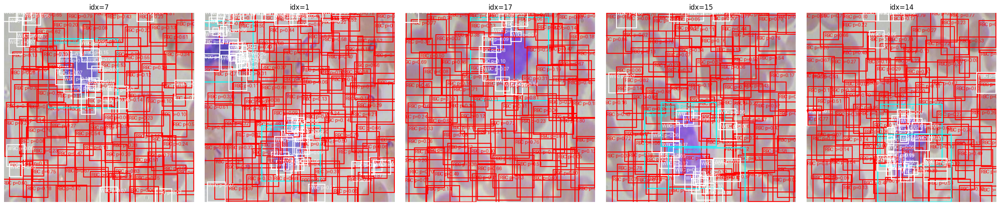

Лог эксперимента сохранён в experiments_log.csv


In [ ]:
experiment = run_yolov3_pipeline(
    model_class=YOLOv3,
    num_classes=3,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    anchors=anchors,
    path_to_dir="/home/eidlin/kag/models/",
    experiment_name="yolov3_hw_main",
    n_epochs=10,
    batch_size=BATCH_SIZE,
    base_lr=1e-4,
    weight_decay=5e-4,
    checkpoint_name="checkpoint_yolov3.pth",
    results_csv_path="experiments_log.csv",
    print_freq=24,
)


### Анализ детекций базовой модели

Ниже представлены предсказания с настройками визуализации, позволяющими оценить локализацию и число срабатываний.

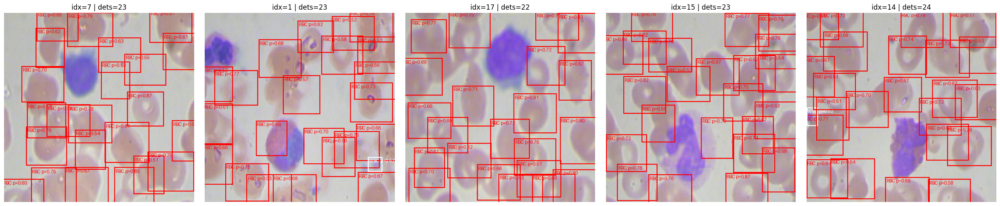

In [49]:
visualize_predictions(
    model=experiment["model"],
    dataset=test_dataset,
    anchors=anchors,
    num_classes=3,
    img_size=IMG_SIZE,
    device=device,
    conf_threshold=experiment["best_conf"],      # те, что подобрал по mAP
    nms_iou_threshold=experiment["best_nms_iou"],
    num_examples=5,
    vis_conf_threshold=0.5,
    max_detections=None,
)


Визуальная оценка показывает пропуски объектов и ложные срабатывания базового детектора.

## 4. Эксперимент: CSP-Darknet backbone

В этом эксперименте исходный backbone заменён на CSP-Darknet с компонентами Conv, Bottleneck, C2f и SPPF. Detection head и общая схема эксперимента сохраняются.

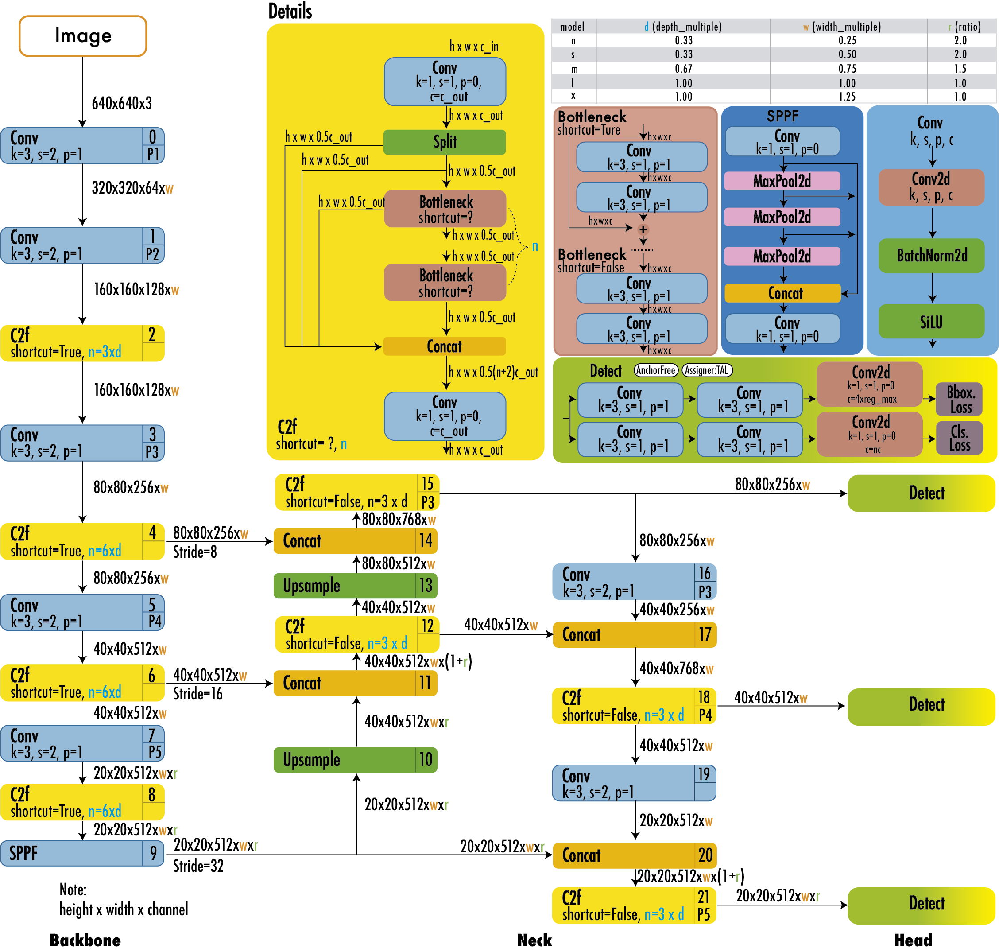

### Архитектурные компоненты CSP-Darknet

Backbone использует последовательности свёрток, нормализацию, SiLU, C2f и SPPF для извлечения признаков на нескольких масштабах.

### C2f

C2f объединяет несколько ветвей признаков, включая bottleneck-блоки, и конкатенирует результаты перед выходной свёрткой.

### SPPF

SPPF агрегирует контекст с помощью последовательного max-pooling и последующего объединения карт признаков.

### Conv block

In [18]:
# При реализации класса запрещено пользоваться ИИ-инструментами.


class Conv(nn.Module):
    def __init__(
        self,
        c_in,
        c_out,
        kernel_size,
        stride=1,
        padding=None,
    ) -> None:
        """
        Инициализация Conv-блока.

        Args:
            c_in: Число входных каналов.
            c_out: Число выходных каналов.
            kernel_size: Размер ядра свертки.
            stride: Шаг свертки.
            padding: Отступ свертки.
        """
        super().__init__()
        if padding is None:
            padding = kernel_size // 2
        self.conv = nn.Conv2d(
            c_in, c_out, kernel_size=kernel_size, stride=stride, padding=padding, bias=False
        )
        self.bn = nn.BatchNorm2d(c_out)
        self.act = nn.SiLU(inplace=True)

    def forward(self, x):
        """Прямой проход через conv-блок."""
        return self.act(self.bn(self.conv(x)))


### Bottleneck block

In [19]:
# При реализации класса запрещено пользоваться ИИ-инструментами.


class Bottleneck(nn.Module):
    """Остаточный bottleneck-блок, используемый внутри C2f."""

    def __init__(
        self,
        c_in: int,
        c_out: int,
        shortcut: bool = True,
        expansion: float = 0.5,
    ) -> None:
        """
        Инициализация bottleneck-блока.

        Args:
            c_in: Число входных каналов.
            c_out: Число выходных каналов.
            shortcut: Использовать ли остаточное соединение.
            expansion: Коэффициент расширения скрытых каналов.
        """
        super().__init__()
        hidden = int(c_out * expansion)
        self.cv1 = Conv(c_in, hidden, kernel_size=1)
        self.cv2 = Conv(hidden, c_out, kernel_size=3)
        self.use_shortcut = shortcut and c_in == c_out

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Прямой проход через bottleneck-блок.

        Args:
            x: Входной тензор формы [B, C, H, W].

        Returns:
            Выходной тензор формы [B, C, H, W].
        """
        y = self.cv2(self.cv1(x))
        return x + y if self.use_shortcut else y


### C2f block

In [20]:
# При реализации класса запрещено пользоваться ИИ-инструментами.


class C2f(nn.Module):
    """C2f-блок по мотивам backbone YOLOv8."""

    def __init__(
        self,
        c_in: int,
        c_out: int,
        n: int = 1,
        shortcut: bool = True,
        expansion: float = 0.5,
    ) -> None:
        """
        Инициализация C2f-блока.

        Args:
            c_in: Число входных каналов.
            c_out: Число выходных каналов.
            n: Число внутренних bottleneck-блоков.
            shortcut: Включать ли остаточные связи в bottleneck-блоках.
            expansion: Коэффициент расширения скрытых каналов.
        """
        super().__init__()
        hidden = int(c_out * expansion)
        self.cv1 = Conv(c_in, hidden * 2, kernel_size=1)
        self.m = nn.ModuleList(
            [Bottleneck(hidden, hidden, shortcut=shortcut, expansion=1.0) for _ in range(n)]
        )
        self.cv2 = Conv(hidden * (2 + n), c_out, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Прямой проход через C2f-блок.

        Args:
            x: Входной тензор формы [B, C_in, H, W].

        Returns:
            Выходной тензор формы [B, C_out, H, W].
        """
        y1, y2 = torch.chunk(self.cv1(x), chunks=2, dim=1)
        outputs = [y1, y2]
        for block in self.m:
            outputs.append(block(outputs[-1]))
        return self.cv2(torch.cat(outputs, dim=1))


### SPPF block

In [21]:
# При реализации класса запрещено пользоваться ИИ-инструментами.


class SPPF(nn.Module):
    """SPPF-блок по мотивам backbone YOLOv8."""

    def __init__(
        self,
        c_in: int,
        c_out: int,
    ) -> None:
        """
        Инициализация SPPF-блока.

        Args:
            c_in: Число входных каналов.
            c_out: Число выходных каналов.
        """
        super().__init__()
        hidden = c_in // 2
        self.cv1 = Conv(c_in, hidden, kernel_size=1)
        self.cv2 = Conv(hidden * 4, c_out, kernel_size=1)
        self.pool = nn.MaxPool2d(kernel_size=5, stride=1, padding=2)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Прямой проход через SPPF-блок.

        Args:
            x: Входной тензор формы [B, C_in, H, W].

        Returns:
            Выходной тензор формы [B, C_out, H, W].
        """
        x = self.cv1(x)
        y1 = self.pool(x)
        y2 = self.pool(y1)
        y3 = self.pool(y2)
        return self.cv2(torch.cat([x, y1, y2, y3], dim=1))


### CSP-Darknet backbone

In [22]:
# При реализации класса запрещено пользоваться ИИ-инструментами.


class YOLOv8Backbone(nn.Module):
    """Backbone в стиле YOLOv8 на основе сверточных и C2f-блоков."""

    def __init__(self) -> None:
        """Инициализация backbone конфигурации S."""
        super().__init__()
        # Базовые каналы под множители (w=0.5 для конфигурации S)
        c1, c2, c3, c4 = 32, 64, 128, 256
        self.stem = Conv(3, c1, kernel_size=3, stride=2)
        self.stage2 = nn.Sequential(
            Conv(c1, c2, kernel_size=3, stride=2),
            C2f(c2, c2, n=1),
        )
        self.stage3 = nn.Sequential(
            Conv(c2, c3, kernel_size=3, stride=2),
            C2f(c3, c3, n=2),
        )
        self.stage4 = nn.Sequential(
            Conv(c3, c4, kernel_size=3, stride=2),
            C2f(c4, c4, n=1),
            SPPF(c4, c4),
        )

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        Прямой проход backbone и получение многоуровневых карт признаков.

        Args:
            x: Пакет изображений формы [B, 3, H, W].

        Returns:
            Кортеж карт признаков дя уровней детекции, например (P3, P4, P5).
        """
        x = self.stem(x)
        p3 = self.stage2(x)
        p4 = self.stage3(p3)
        p5 = self.stage4(p4)
        return p3, p4, p5


### YOLOv3 с CSP-Darknet

In [23]:
class YOLOv3_CSPDarknet(nn.Module):
    """Модификация YOLOv3 с CSP-Darknet в стиле YOLOv8."""

    def __init__(self, num_classes: int = NUM_CLASSES) -> None:
        """
        Инициализация модели YOLOv3 с новым backbone.

        Args:
            num_classes: Число классов объектов.
        """
        super().__init__()
        self.backbone: YOLOv8Backbone = YOLOv8Backbone()
        self.num_classes: int = num_classes
        self.num_anchors: int = 3

        # Лёгкий neck: просто даунсемплим фичи до тех же spatial-размеров,
        # что и в базовом YOLOv3:
        #   p3: 104x104 -> 52x52  (stride 4 -> 8)
        #   p4:  52x52  -> 26x26  (stride 8 -> 16)
        #   p5:  26x26  -> 13x13  (stride 16 -> 32)
        self.down_p3 = Conv(64, 64, kernel_size=3, stride=2)    # 104 -> 52
        self.down_p4 = Conv(128, 128, kernel_size=3, stride=2)  # 52  -> 26
        self.down_p5 = Conv(256, 256, kernel_size=3, stride=2)  # 26  -> 13

        # Головы детекции для трёх масштабов.
        # Важно только, чтобы выходной канал = num_anchors * (5 + num_classes)
        out_ch = self.num_anchors * (5 + num_classes)
        self.head = nn.ModuleList(
            [
                nn.Conv2d(256, out_ch, kernel_size=1),  # будет сидеть на P5 (13x13)
                nn.Conv2d(128, out_ch, kernel_size=1),  # на P4 (26x26)
                nn.Conv2d(64, out_ch, kernel_size=1),   # на P3 (52x52)
            ]
        )

    def _format_output(self, tensor: torch.Tensor) -> torch.Tensor:
        """
        Переформатирование выхода головы детекции.

        Args:
            tensor: Тензор предсказаний формы [B, C, H, W].

        Returns:
            Тензор формы [B, H, W, num_anchors, C_per_anchor].
        """
        b, c, h, w = tensor.shape
        tensor = tensor.view(b, self.num_anchors, -1, h, w)
        tensor = tensor.permute(0, 3, 4, 1, 2).contiguous()
        return tensor

    def forward(self, x: torch.Tensor) -> list[torch.Tensor]:
        """
        Прямой проход модели YOLOv3 с C2f-бэкбоном.

        Args:
            x: Пакет изображений формы [B, 3, H, W].

        Returns:
            Список тензоров предсказаний для разных уровней признаков.
        """
        # Фичи backbone: p3: [B, 64, 104,104], p4: [B,128, 52,52], p5: [B,256, 26,26]
        p3, p4, p5 = self.backbone(x)

        # Даунсемплинг до тех же размеров, что в оригинальном YOLOv3
        f3 = self.down_p3(p3)   # -> [B, 64, 52, 52]
        f4 = self.down_p4(p4)   # -> [B,128, 26, 26]
        f5 = self.down_p5(p5)   # -> [B,256, 13, 13]

        # Подаём на головы в порядке P5, P4, P3,
        # чтобы первый элемент списка соответствовал grid_size=13 и stride=32
        raw_p5 = self.head[0](f5)  # [B, out_ch, 13,13]
        raw_p4 = self.head[1](f4)  # [B, out_ch, 26,26]
        raw_p3 = self.head[2](f3)  # [B, out_ch, 52,52]

        out_p5 = self._format_output(raw_p5)
        out_p4 = self._format_output(raw_p4)
        out_p3 = self._format_output(raw_p3)

        # порядок [P5, P4, P3] — как у базового YOLOv3
        return [out_p5, out_p4, out_p3]


2) Инициализация модели и оптимизатора...
   Чекпоинт не найден — начинаем обучение с нуля.
3) Обучение модели...
Epoch: 0/30	Batch 0/96	Loss 6.7719 (6.7719)	
Epoch: 0/30	Batch 24/96	Loss 4.8271 (8.9622)	
Epoch: 0/30	Batch 48/96	Loss 4.2823 (6.6871)	
Epoch: 0/30	Batch 72/96	Loss 3.8145 (6.3454)	
Epoch: 1/30	Batch 0/96	Loss 3.5057 (3.5057)	
Epoch: 1/30	Batch 24/96	Loss 3.4167 (10.4188)	
Epoch: 1/30	Batch 48/96	Loss 3.1104 (7.7963)	
Epoch: 1/30	Batch 72/96	Loss 2.8880 (6.9359)	
Epoch: 2/30	Batch 0/96	Loss 2.7858 (2.7858)	
Epoch: 2/30	Batch 24/96	Loss 2.6390 (4.2360)	
Epoch: 2/30	Batch 48/96	Loss 2.6011 (5.1984)	
Epoch: 2/30	Batch 72/96	Loss 2.4347 (5.4538)	
Epoch: 3/30	Batch 0/96	Loss 2.4034 (2.4034)	
Epoch: 3/30	Batch 24/96	Loss 2.4591 (5.6972)	
Epoch: 3/30	Batch 48/96	Loss 2.4229 (5.8775)	
Epoch: 3/30	Batch 72/96	Loss 2.2236 (5.7941)	
Epoch: 4/30	Batch 0/96	Loss 2.1957 (2.1957)	
Epoch: 4/30	Batch 24/96	Loss 2.0702 (5.4294)	
Epoch: 4/30	Batch 48/96	Loss 2.2567 (4.4697)	
Epoch: 4/30	Batc

/home/eidlin/miniconda3/envs/OlympAgents/lib/python3.10/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


  -> conf=0.05, nms_iou=0.50
  -> conf=0.05, nms_iou=0.70
  -> conf=0.10, nms_iou=0.30
  -> conf=0.10, nms_iou=0.50
  -> conf=0.10, nms_iou=0.70
  -> conf=0.20, nms_iou=0.30
  -> conf=0.20, nms_iou=0.50
  -> conf=0.20, nms_iou=0.70
  -> conf=0.30, nms_iou=0.30
  -> conf=0.30, nms_iou=0.50
  -> conf=0.30, nms_iou=0.70
  -> conf=0.40, nms_iou=0.30
  -> conf=0.40, nms_iou=0.50
  -> conf=0.40, nms_iou=0.70
  -> conf=0.50, nms_iou=0.30
  -> conf=0.50, nms_iou=0.50
  -> conf=0.50, nms_iou=0.70

Лучшие пороги: conf=0.050, nms_iou=0.500, mAP@.50:.95=0.2396
   Лучшие пороги: conf=0.050, nms_iou=0.500

5–6) Оценка качества и времени работы на тестовом датасете...

   Test mAP@.50:.95 = 0.2208
   Test mAP@.50     = 0.5993
   Test mAP@.75     = 0.0472
   Среднее время инференса на тесте: 238.72 ms / изображение

7) Визуализация детекций на примерах из тестового датасета...


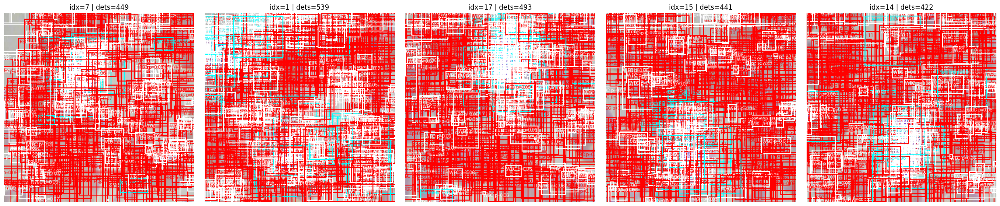

Лог эксперимента сохранён в experiments_log.csv


In [26]:
experiment_add_new_backbone = run_yolov3_pipeline(
    model_class=YOLOv3_CSPDarknet,
    num_classes=3,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    anchors=anchors,
    path_to_dir="/home/eidlin/kag/models/",
    experiment_name="yolov3_add_backbone_hw_main",
    n_epochs=30,
    batch_size=BATCH_SIZE,
    base_lr=1e-4,
    weight_decay=5e-4,
    checkpoint_name="checkpoint_yolov3_add_backbone.pth",
    results_csv_path="experiments_log.csv",
    print_freq=24,
)


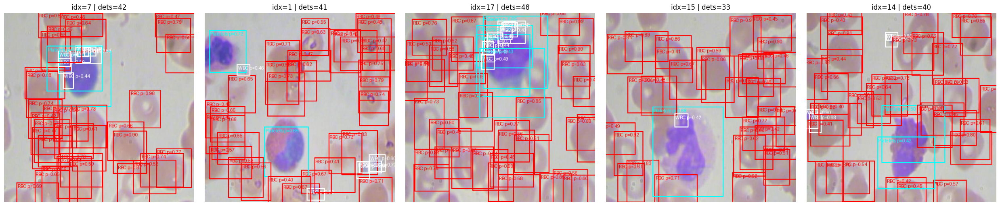

In [27]:
visualize_predictions(
    model=experiment_add_new_backbone["model"],
    dataset=test_dataset,
    anchors=anchors,
    num_classes=3,
    img_size=IMG_SIZE,
    device=device,
    conf_threshold=experiment_add_new_backbone["best_conf"],      # те, что подобрал по mAP
    nms_iou_threshold=experiment_add_new_backbone["best_nms_iou"],
    num_examples=5,
    vis_conf_threshold=0.4,
    max_detections=None,
)


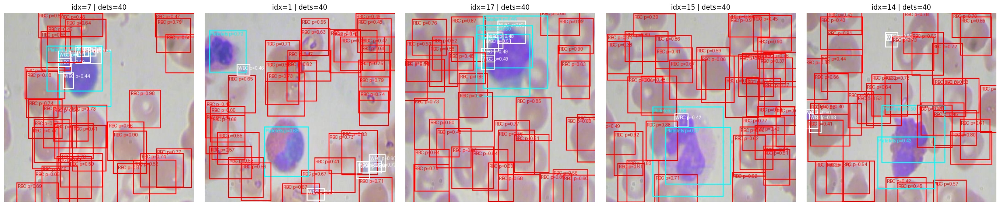

In [28]:
visualize_predictions(
    model=experiment_add_new_backbone["model"],
    dataset=test_dataset,
    anchors=anchors,
    num_classes=3,
    img_size=IMG_SIZE,
    device=device,
    conf_threshold=experiment_add_new_backbone["best_conf"],      # те, что подобрал по mAP
    nms_iou_threshold=experiment_add_new_backbone["best_nms_iou"],
    num_examples=5,
    vis_conf_threshold=None,
    max_detections=40,
)


### Анализ результатов CSP-Darknet

Замена backbone увеличила test mAP@0.50:0.95 с 0.1668 до 0.2208. Визуализации ниже и выше позволяют сравнить характер детекций.

## 5. Эксперимент: PAN-FPN neck

К backbone CSP-Darknet добавлен PAN-FPN neck с top-down и bottom-up передачей признаков между масштабами.

### Реализация PAN-FPN

In [24]:
# При реализации класса запрещено пользоваться ИИ-инструментами.


class YOLONeck_PAN(nn.Module):
    """Neck в стиле YOLOv8: PAN-FPN с bottom-up и top-down путями."""

    def __init__(self) -> None:
        """Инициализация PAN-нейка на C2f-блоках."""
        super().__init__()
        # Используем каналы, совместимые с backbone YOLOv8 S
        self.reduce_p5 = Conv(256, 128, kernel_size=1)
        self.reduce_p4 = Conv(128, 64, kernel_size=1)

        self.c2f_td4 = C2f(128 + 128, 128, n=1)
        self.c2f_td3 = C2f(64 + 64, 64, n=1)

        self.down_p3 = Conv(64, 64, kernel_size=3, stride=2)
        self.c2f_bu4 = C2f(64 + 128, 128, n=1)

        self.down_p4 = Conv(128, 128, kernel_size=3, stride=2)
        self.c2f_bu5 = C2f(128 + 256, 256, n=1)

    def forward(
        self,
        p3: torch.Tensor,
        p4: torch.Tensor,
        p5: torch.Tensor,
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        Прямой проход через PAN-нейк.

        Args:
            p3: Карта признаков низкого уровня (наиболее высокое разрешение).
            p4: Среднеуровневая карта признаков.
            p5: Карта признаков высокого уровня (наименьшее разрешение).

        Returns:
            Кортеж из трёх обновлённых карт признаков:
            (P3_out, P4_out, P5_out).
        """
        p5_red = self.reduce_p5(p5)
        p5_up = F.interpolate(p5_red, scale_factor=2, mode="nearest")
        p4_td = self.c2f_td4(torch.cat([p5_up, p4], dim=1))

        p4_red = self.reduce_p4(p4_td)
        p4_up = F.interpolate(p4_red, scale_factor=2, mode="nearest")
        p3_td = self.c2f_td3(torch.cat([p4_up, p3], dim=1))

        p3_down = self.down_p3(p3_td)
        p4_bu = self.c2f_bu4(torch.cat([p3_down, p4_td], dim=1))

        p4_down = self.down_p4(p4_bu)
        p5_bu = self.c2f_bu5(torch.cat([p4_down, p5], dim=1))

        return p3_td, p4_bu, p5_bu


### Интеграция PAN-FPN в детектор

In [25]:
class YOLOv3_CSPDarknet_PAN(nn.Module):
    """YOLOv3 с YOLOv8-backbone и PAN-нейком, совместимый с текущим YoloLoss/TargetBuilder."""

    def __init__(self, num_classes: int = NUM_CLASSES) -> None:
        super().__init__()
        self.backbone: nn.Module = YOLOv8Backbone()
        self.neck: YOLONeck_PAN = YOLONeck_PAN()
        self.num_classes: int = num_classes
        self.num_anchors: int = 3

        # после PAN у нас:
        #   p3: [B, 64, 104,104]
        #   p4: [B,128, 52, 52]
        #   p5: [B,256, 26, 26]
        # нужно получить:
        #   f3: [B, 64, 52, 52]
        #   f4: [B,128, 26, 26]
        #   f5: [B,256, 13, 13]
        self.post_down_p3 = Conv(64, 64, kernel_size=3, stride=2)    # 104 -> 52
        self.post_down_p4 = Conv(128, 128, kernel_size=3, stride=2)  # 52  -> 26
        self.post_down_p5 = Conv(256, 256, kernel_size=3, stride=2)  # 26  -> 13

        out_ch = self.num_anchors * (num_classes + 5)
        # головы в порядке P5, P4, P3
        self.head = nn.ModuleList(
            [
                nn.Conv2d(256, out_ch, kernel_size=1),  # для P5 (13x13)
                nn.Conv2d(128, out_ch, kernel_size=1),  # для P4 (26x26)
                nn.Conv2d(64, out_ch, kernel_size=1),   # для P3 (52x52)
            ]
        )

    def _format_output(self, tensor: torch.Tensor) -> torch.Tensor:
        b, c, h, w = tensor.shape
        tensor = tensor.view(b, self.num_anchors, -1, h, w)
        tensor = tensor.permute(0, 3, 4, 1, 2).contiguous()
        return tensor

    def forward(self, x: torch.Tensor) -> list[torch.Tensor]:
        # backbone + PAN
        p3, p4, p5 = self.backbone(x)            # исходные фичи
        p3, p4, p5 = self.neck(p3, p4, p5)       # PAN-обновлённые фичи

        # приведение к YOLOv3-совместимым размерам
        f3 = self.post_down_p3(p3)   # [B, 64, 52, 52]
        f4 = self.post_down_p4(p4)   # [B,128, 26, 26]
        f5 = self.post_down_p5(p5)   # [B,256, 13, 13]

        # головы в порядке P5, P4, P3
        raw_p5 = self.head[0](f5)
        raw_p4 = self.head[1](f4)
        raw_p3 = self.head[2](f3)

        out_p5 = self._format_output(raw_p5)
        out_p4 = self._format_output(raw_p4)
        out_p3 = self._format_output(raw_p3)

        # возвращаем [P5, P4, P3], как базовый YOLOv3
        return [out_p5, out_p4, out_p3]


### Обучение и оценка конфигурации с PAN-FPN

2) Инициализация модели и оптимизатора...
   Чекпоинт не найден — начинаем обучение с нуля.
3) Обучение модели...
Epoch: 0/30	Batch 0/96	Loss 6.3131 (6.3131)	
Epoch: 0/30	Batch 24/96	Loss 4.7713 (9.3996)	
Epoch: 0/30	Batch 48/96	Loss 4.5752 (7.1023)	
Epoch: 0/30	Batch 72/96	Loss 3.9690 (6.8820)	
Epoch: 1/30	Batch 0/96	Loss 4.0043 (4.0043)	
Epoch: 1/30	Batch 24/96	Loss 3.5304 (3.6395)	
Epoch: 1/30	Batch 48/96	Loss 3.3037 (6.4223)	
Epoch: 1/30	Batch 72/96	Loss 3.0673 (6.5857)	
Epoch: 2/30	Batch 0/96	Loss 3.0054 (3.0054)	
Epoch: 2/30	Batch 24/96	Loss 2.8710 (6.9623)	
Epoch: 2/30	Batch 48/96	Loss 2.8151 (4.9642)	
Epoch: 2/30	Batch 72/96	Loss 2.7701 (6.4743)	
Epoch: 3/30	Batch 0/96	Loss 2.5119 (2.5119)	
Epoch: 3/30	Batch 24/96	Loss 2.6348 (4.6556)	
Epoch: 3/30	Batch 48/96	Loss 2.4322 (5.2561)	
Epoch: 3/30	Batch 72/96	Loss 2.2981 (4.3229)	
Epoch: 4/30	Batch 0/96	Loss 2.4269 (2.4269)	
Epoch: 4/30	Batch 24/96	Loss 2.4118 (7.1373)	
Epoch: 4/30	Batch 48/96	Loss 3.7658 (6.8462)	
Epoch: 4/30	Batch

/home/eidlin/miniconda3/envs/OlympAgents/lib/python3.10/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


  -> conf=0.05, nms_iou=0.50
  -> conf=0.05, nms_iou=0.70
  -> conf=0.10, nms_iou=0.30
  -> conf=0.10, nms_iou=0.50
  -> conf=0.10, nms_iou=0.70
  -> conf=0.20, nms_iou=0.30
  -> conf=0.20, nms_iou=0.50
  -> conf=0.20, nms_iou=0.70
  -> conf=0.30, nms_iou=0.30
  -> conf=0.30, nms_iou=0.50
  -> conf=0.30, nms_iou=0.70
  -> conf=0.40, nms_iou=0.30
  -> conf=0.40, nms_iou=0.50
  -> conf=0.40, nms_iou=0.70
  -> conf=0.50, nms_iou=0.30
  -> conf=0.50, nms_iou=0.50
  -> conf=0.50, nms_iou=0.70

Лучшие пороги: conf=0.050, nms_iou=0.700, mAP@.50:.95=0.1497
   Лучшие пороги: conf=0.050, nms_iou=0.700

5–6) Оценка качества и времени работы на тестовом датасете...

   Test mAP@.50:.95 = 0.1582
   Test mAP@.50     = 0.4896
   Test mAP@.75     = 0.0415
   Среднее время инференса на тесте: 680.06 ms / изображение

7) Визуализация детекций на примерах из тестового датасета...


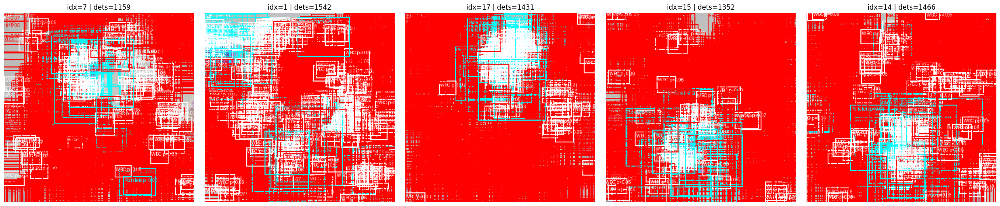

Лог эксперимента сохранён в experiments_log.csv


In [30]:
experiment_pan = run_yolov3_pipeline(
    model_class=YOLOv3_CSPDarknet_PAN,
    num_classes=3,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    anchors=anchors,
    path_to_dir="/home/eidlin/kag/models/",
    experiment_name="yolov3_csp_pan_hw_main",
    n_epochs=30,
    batch_size=BATCH_SIZE,
    base_lr=1e-4,
    weight_decay=5e-4,
    checkpoint_name="checkpoint_yolov3_csp_pan.pth",
    results_csv_path="experiments_log.csv",
    print_freq=24,
)


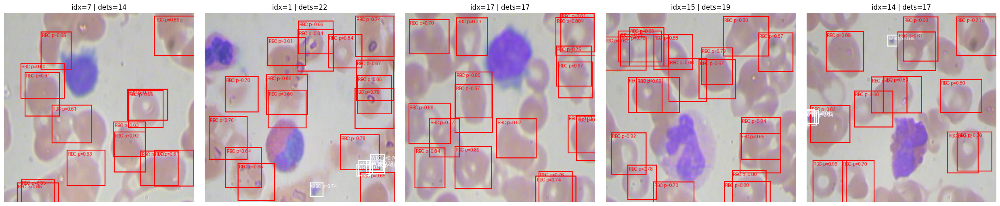

In [ ]:
visualize_predictions(
    model=experiment_pan["model"],
    dataset=test_dataset,
    anchors=anchors,
    num_classes=3,
    img_size=IMG_SIZE,
    device=device,
    conf_threshold=experiment_pan["best_conf"],      # те, что подобрал по mAP
    nms_iou_threshold=experiment_pan["best_nms_iou"],
    num_examples=5,
    vis_conf_threshold=0.5,
    max_detections=None,
)


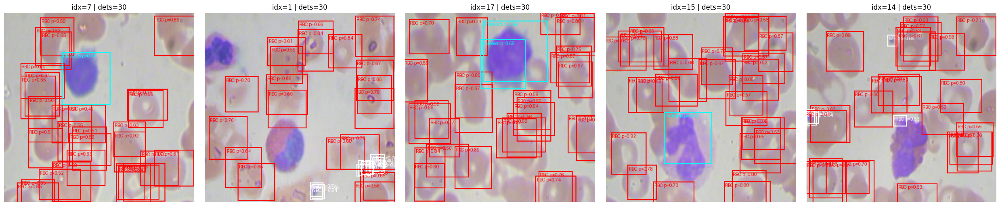

In [34]:
visualize_predictions(
    model=experiment_pan["model"],
    dataset=test_dataset,
    anchors=anchors,
    num_classes=3,
    img_size=IMG_SIZE,
    device=device,
    conf_threshold=experiment_pan["best_conf"],      # те, что подобрал по mAP
    nms_iou_threshold=experiment_pan["best_nms_iou"],
    num_examples=5,
    vis_conf_threshold=None,
    max_detections=30,
)


### Анализ результатов PAN-FPN

В данном эксперименте test mAP@0.50:0.95 составил 0.1582. Сравнение показывает, что влияние архитектурных изменений необходимо оценивать на одинаковом протоколе.

## 6. Эксперимент: CIoU + Focal Loss

Финальная конфигурация использует CSP-Darknet, PAN-FPN и модифицированную функцию потерь: CIoU для локализации объектов и Focal BCE для objectness и классификации.

### CIoU Loss

CIoU учитывает пересечение предсказанного и целевого боксов, расстояние между центрами и согласованность пропорций. В проекте эта функция используется для регрессии bounding boxes.

### Focal Loss

Focal Loss уменьшает относительный вклад простых примеров и концентрирует обучение на сложных случаях.

### Реализация функций потерь

In [35]:
# При реализации класса запрещено пользоваться ИИ-инструментами.


class BoxCIoULoss(nn.Module):
    """Вычисляет Complete Intersection over Union (CIoU) Loss для координат боксов.

    Потери рассчитываются только для позиций, где присутствует объект (`obj_mask`).
    """

    def __init__(self):
        """Инициализирует слой потерь."""
        super().__init__()
        self.eps = 1e-7

    def forward(
        self, pred_box: torch.Tensor, target_box: torch.Tensor, obj_mask: torch.Tensor
    ) -> torch.Tensor:
        """
        Args:
            pred_box (torch.Tensor): Предсказанные боксы (N, ..., 4) в формате [cx, cy, w, h].
            target_box (torch.Tensor): Истинные боксы (N, ..., 4) в формате [cx, cy, w, h].
            obj_mask (torch.Tensor): Маска (N, ...), отмечающая позиции с объектами.

        Returns:
            torch.Tensor: Скалярное значение потерь.
        """
        if not obj_mask.any():
            return torch.tensor(0.0, device=pred_box.device)

        def xywh_to_xyxy(box):
            x, y, w, h = box.unbind(-1)
            x1 = x - w / 2
            y1 = y - h / 2
            x2 = x + w / 2
            y2 = y + h / 2
            return x1, y1, x2, y2

        px1, py1, px2, py2 = xywh_to_xyxy(pred_box)
        tx1, ty1, tx2, ty2 = xywh_to_xyxy(target_box)

        inter_x1 = torch.max(px1, tx1)
        inter_y1 = torch.max(py1, ty1)
        inter_x2 = torch.min(px2, tx2)
        inter_y2 = torch.min(py2, ty2)

        inter_w = (inter_x2 - inter_x1).clamp(min=0)
        inter_h = (inter_y2 - inter_y1).clamp(min=0)
        inter_area = inter_w * inter_h

        area_p = (px2 - px1).clamp(min=0) * (py2 - py1).clamp(min=0)
        area_t = (tx2 - tx1).clamp(min=0) * (ty2 - ty1).clamp(min=0)
        union = area_p + area_t - inter_area + self.eps
        iou = inter_area / union

        center_dist = (pred_box[..., 0] - target_box[..., 0]) ** 2 + (pred_box[..., 1] - target_box[..., 1]) ** 2

        enclose_x1 = torch.min(px1, tx1)
        enclose_y1 = torch.min(py1, ty1)
        enclose_x2 = torch.max(px2, tx2)
        enclose_y2 = torch.max(py2, ty2)
        c2 = (enclose_x2 - enclose_x1) ** 2 + (enclose_y2 - enclose_y1) ** 2 + self.eps

        v = (4.0 / math.pi**2) * (
            torch.atan(target_box[..., 2] / (target_box[..., 3] + self.eps))
            - torch.atan(pred_box[..., 2] / (pred_box[..., 3] + self.eps))
        ) ** 2
        with torch.no_grad():
            alpha = v / (1 - iou + v + self.eps)

        ciou = iou - center_dist / c2 - alpha * v
        loss = 1 - ciou

        loss = loss * obj_mask  # broadcast по последней размерности
        denom = obj_mask.sum().clamp(min=1)
        return loss.sum() / denom


class ObjectnessFocalLoss(nn.Module):
    """Вычисляет Focal Loss для предсказания наличия объекта (`objectness`).

    Раздельно обрабатывает позиции с объектами (`obj_mask`) и без них (`noobj_mask`),
    чтобы бороться с дисбалансом классов.
    """

    def __init__(self, gamma: float = 2.0, alpha: float = 0.25):
        """Инициализирует слой потерь."""
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss(reduction="none")
        self.gamma = gamma
        self.alpha = alpha

    def forward(
        self,
        pred_obj: torch.Tensor,
        target_obj: torch.Tensor,
        obj_mask: torch.Tensor,
        noobj_mask: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            pred_obj (torch.Tensor): Предсказанные логиты `objectness` (N, ..., 1).
            target_obj (torch.Tensor): Истинные метки `objectness` (0 или 1) (N, ..., 1).
            obj_mask (torch.Tensor): Маска позиций с объектами.
            noobj_mask (torch.Tensor): Маска позиций без объектов (фон).

        Returns:
            torch.Tensor: Скалярное значение потерь.
        """
        loss = self.bce(pred_obj, target_obj)
        prob = torch.sigmoid(pred_obj)
        focal_factor_pos = (1 - prob) ** self.gamma
        focal_factor_neg = (prob) ** self.gamma

        obj_mask_exp = obj_mask.unsqueeze(-1)
        noobj_mask_exp = noobj_mask.unsqueeze(-1)
        pos_loss = self.alpha * loss * focal_factor_pos * obj_mask_exp
        neg_loss = (1 - self.alpha) * loss * focal_factor_neg * noobj_mask_exp
        
        denom = (obj_mask + noobj_mask).sum().clamp(min=1)
        return (pos_loss + neg_loss).sum() / denom


class ClassFocalLoss(nn.Module):
    """Вычисляет Focal Loss для задачи классификации объектов.

    Потери рассчитываются только для позиций, где присутствует объект (`obj_mask`).
    """

    def __init__(self, gamma: float = 2.0, alpha: float = 0.25):
        """Инициализирует слой потерь."""
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss(reduction="none")
        self.gamma = gamma
        self.alpha = alpha

    def forward(
        self, pred_class: torch.Tensor, target_class: torch.Tensor, obj_mask: torch.Tensor
    ) -> torch.Tensor:
        """
        Args:
            pred_class (torch.Tensor): Предсказанные логиты классов (N, ..., C).
            target_class (torch.Tensor): Истинные метки классов (N, ..., C), обычно one-hot.
            obj_mask (torch.Tensor): Маска (N, ...), отмечающая позиции с объектами.

        Returns:
            torch.Tensor: Скалярное значение потерь.
        """
        loss = self.bce(pred_class, target_class)
        prob = torch.sigmoid(pred_class)
        focal_factor = (1 - prob) ** self.gamma

        obj_mask_exp = obj_mask.unsqueeze(-1)
        loss = self.alpha * loss * focal_factor * obj_mask_exp

        denom = obj_mask_exp.sum().clamp(min=1)
        return loss.sum() / denom


In [38]:
class YoloLossCIoUHybrid(nn.Module):
    """
    Вариант YOLO-лосса:
      - регрессия боксов через CIoU (BoxCIoULoss),
      - objectness и классы через Focal BCE.
    Использует существующий TargetBuilder, так что формат таргетов тот же.
    """

    def __init__(self, anchors_by_scale, num_classes=3, ignore_thresh=0.5):
        super().__init__()
        self.target_builder = TargetBuilder(anchors_by_scale, num_classes, ignore_thresh)

        self.box_loss_fn = BoxCIoULoss()
        self.obj_loss_fn = ObjectnessLoss()
        self.cls_loss_fn = ClassLoss()

        # веса компонентов — как в исходном YoloLoss
        self.lambda_class = 1.0
        self.lambda_obj = 1.0
        self.lambda_noobj = 10.0
        self.lambda_box = 10.0

    def _decode_xywh(
        self,
        pred_box_param: torch.Tensor,
        target_box_param: torch.Tensor,
        scale_idx: int,
        S: int,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """
        Декодирует (tx,ty,tw,th) + таргеты в реальные боксы [cx, cy, w, h] в "сеточных" единицах.

        pred_box_param, target_box_param: [B, S, S, A, 4]
        """
        device = pred_box_param.device
        B, _, _, A, _ = pred_box_param.shape

        # Анкеры в "grid-единицах" и страйд
        anchors_grid = self.target_builder.anchors_grid_units[scale_idx].to(device)  # [A,2]
        stride = self.target_builder.strides[scale_idx]

        anchor_w_grid = anchors_grid[:, 0].view(1, 1, 1, A)
        anchor_h_grid = anchors_grid[:, 1].view(1, 1, 1, A)

        # индексы ячеек
        gy, gx = torch.meshgrid(
            torch.arange(S, device=device),
            torch.arange(S, device=device),
            indexing="ij",
        )
        gx = gx.view(1, S, S, 1)
        gy = gy.view(1, S, S, 1)

        # --- предсказания ---
        tx_raw = pred_box_param[..., 0]
        ty_raw = pred_box_param[..., 1]
        tw_raw = pred_box_param[..., 2]
        th_raw = pred_box_param[..., 3]

        # как в YOLO: смещение внутри ячейки через sigmoid
        dx_pred = torch.sigmoid(tx_raw)
        dy_pred = torch.sigmoid(ty_raw)

        cx_pred = (gx + dx_pred) * stride
        cy_pred = (gy + dy_pred) * stride

        pw_grid = anchor_w_grid * torch.exp(tw_raw)
        ph_grid = anchor_h_grid * torch.exp(th_raw)
        pw_pred = pw_grid * stride
        ph_pred = ph_grid * stride

        pred_xywh = torch.stack([cx_pred, cy_pred, pw_pred, ph_pred], dim=-1)

        # --- таргеты ---
        dx_tgt = target_box_param[..., 0]
        dy_tgt = target_box_param[..., 1]
        log_dw_tgt = target_box_param[..., 2]
        log_dh_tgt = target_box_param[..., 3]

        cx_tgt = (gx + dx_tgt) * stride
        cy_tgt = (gy + dy_tgt) * stride

        pw_grid_tgt = anchor_w_grid * torch.exp(log_dw_tgt)
        ph_grid_tgt = anchor_h_grid * torch.exp(log_dh_tgt)
        pw_tgt = pw_grid_tgt * stride
        ph_tgt = ph_grid_tgt * stride

        target_xywh = torch.stack([cx_tgt, cy_tgt, pw_tgt, ph_tgt], dim=-1)

        return pred_xywh, target_xywh

    def forward(self, predictions, targets):
        """
        predictions: список тензоров [B, S, S, A, 5+C] в порядке [P5, P4, P3]
        targets: (N, 6)  [batch_idx, class_id, cx, cy, w, h] (нормированные)
        """
        obj_masks, noobj_masks, target_tensors = self.target_builder(predictions, targets)

        total_loss = 0.0
        B = predictions[0].shape[0]

        for scale_idx, p in enumerate(predictions):
            S = p.shape[1]

            pred_box_param = p[..., 0:4]
            pred_obj = p[..., 4:5]
            pred_class = p[..., 5:]

            target_box_param = target_tensors[scale_idx][..., 0:4]
            target_obj = target_tensors[scale_idx][..., 4:5]
            target_class = target_tensors[scale_idx][..., 5:]

            obj_mask = obj_masks[scale_idx]
            noobj_mask = noobj_masks[scale_idx]

            # декодируем в xywh (пиксели) под CIoU
            pred_xywh, target_xywh = self._decode_xywh(
                pred_box_param, target_box_param, scale_idx, S
            )

            loss_box = self.box_loss_fn(pred_xywh, target_xywh, obj_mask)
            loss_obj, loss_noobj = self.obj_loss_fn(pred_obj, target_obj, obj_mask, noobj_mask)
            loss_class = self.cls_loss_fn(pred_class, target_class, obj_mask)

            scale_loss = (
                self.lambda_box * loss_box
                + self.lambda_obj * loss_obj
                + self.lambda_noobj * loss_noobj
                + self.lambda_class * loss_class
            )

            total_loss += scale_loss

        return total_loss / B


### Обучение и оценка финальной конфигурации

2) Инициализация модели и оптимизатора...
   Чекпоинт не найден — начинаем обучение с нуля.
3) Обучение модели...
Epoch: 0/30	Batch 0/96	Loss 4.8834 (4.8834)	
Epoch: 0/30	Batch 24/96	Loss 4.3942 (4.5552)	
Epoch: 0/30	Batch 48/96	Loss 4.1967 (4.3967)	
Epoch: 0/30	Batch 72/96	Loss 3.9369 (4.2760)	
Epoch: 1/30	Batch 0/96	Loss 3.9308 (3.9308)	
Epoch: 1/30	Batch 24/96	Loss 3.6680 (3.7040)	
Epoch: 1/30	Batch 48/96	Loss 3.5140 (3.6323)	
Epoch: 1/30	Batch 72/96	Loss 3.3096 (3.5745)	
Epoch: 2/30	Batch 0/96	Loss 3.2138 (3.2138)	
Epoch: 2/30	Batch 24/96	Loss 3.1876 (3.1972)	
Epoch: 2/30	Batch 48/96	Loss 3.0672 (3.1532)	
Epoch: 2/30	Batch 72/96	Loss 2.7882 (3.0967)	
Epoch: 3/30	Batch 0/96	Loss 2.7990 (2.7990)	
Epoch: 3/30	Batch 24/96	Loss 2.8035 (2.8192)	
Epoch: 3/30	Batch 48/96	Loss 2.7196 (2.7837)	
Epoch: 3/30	Batch 72/96	Loss 2.6347 (2.7391)	
Epoch: 4/30	Batch 0/96	Loss 2.6021 (2.6021)	
Epoch: 4/30	Batch 24/96	Loss 2.5602 (2.4945)	
Epoch: 4/30	Batch 48/96	Loss 2.4955 (2.4673)	
Epoch: 4/30	Batch

/home/eidlin/miniconda3/envs/OlympAgents/lib/python3.10/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


  -> conf=0.10, nms_iou=0.30
  -> conf=0.10, nms_iou=0.50
  -> conf=0.10, nms_iou=0.70
  -> conf=0.20, nms_iou=0.30
  -> conf=0.20, nms_iou=0.50
  -> conf=0.20, nms_iou=0.70
  -> conf=0.30, nms_iou=0.30
  -> conf=0.30, nms_iou=0.50
  -> conf=0.30, nms_iou=0.70
  -> conf=0.40, nms_iou=0.30
  -> conf=0.40, nms_iou=0.50
  -> conf=0.40, nms_iou=0.70
  -> conf=0.50, nms_iou=0.30
  -> conf=0.50, nms_iou=0.50
  -> conf=0.50, nms_iou=0.70

Лучшие пороги: conf=0.050, nms_iou=0.500, mAP@.50:.95=0.4572
   Лучшие пороги: conf=0.050, nms_iou=0.500

5–6) Оценка качества и времени работы на тестовом датасете...

   Test mAP@.50:.95 = 0.4302
   Test mAP@.50     = 0.8053
   Test mAP@.75     = 0.4588
   Среднее время инференса на тесте: 36.33 ms / изображение

7) Визуализация детекций на примерах из тестового датасета...


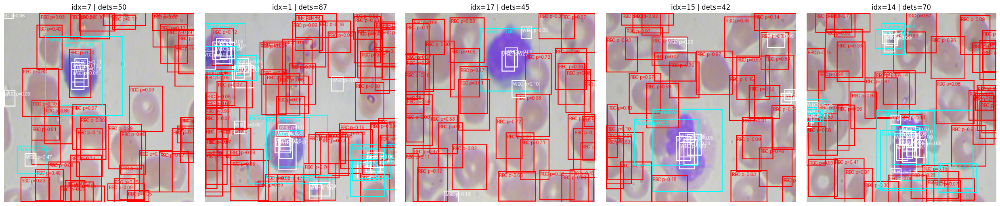

Лог эксперимента сохранён в experiments_log.csv


In [40]:
experiment_pan_ciou_hybrid = run_yolov3_pipeline(
    model_class=YOLOv3_CSPDarknet_PAN,   # PAN-модель
    num_classes=3,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    anchors=anchors,
    path_to_dir="/home/eidlin/kag/models/",
    experiment_name="yolov3_csp_pan_ciou_hybrid",
    n_epochs=30,
    batch_size=BATCH_SIZE,
    base_lr=1e-4,
    weight_decay=5e-4,
    checkpoint_name="checkpoint_yolov3_csp_pan_ciou_hybrid.pth",
    results_csv_path="experiments_log.csv",
    print_freq=24,
    loss_class=YoloLossCIoUHybrid,      # <-- главное изменение
)


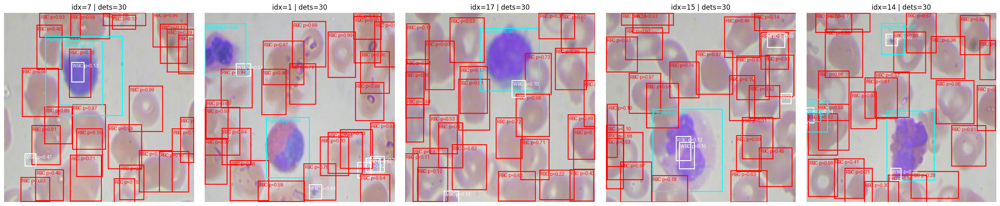

In [42]:
visualize_predictions(
    model=experiment_pan_ciou_hybrid["model"],
    dataset=test_dataset,
    anchors=anchors,
    num_classes=3,
    img_size=IMG_SIZE,
    device=device,
    conf_threshold=experiment_pan_ciou_hybrid["best_conf"], 
    nms_iou_threshold=experiment_pan_ciou_hybrid["best_nms_iou"],
    num_examples=5,
    vis_conf_threshold=None,
    max_detections=30,
)


### Анализ результатов финальной модели

Финальная конфигурация достигла test mAP@0.50:0.95 = **0.4302** и test mAP@0.50 = **0.8053**. На визуализациях можно сравнить локализацию и характер ложных детекций.

## 7. Итоги экспериментов

Сопоставление результатов четырёх конфигураций на тестовой выборке:

| Конфигурация | Test mAP@0.50:0.95 |
|---|---:|
| YOLOv3 | 0.1668 |
| + CSP-Darknet | 0.2208 |
| + PAN-FPN | 0.1582 |
| + CIoU / Focal Loss | **0.4302** |

Финальная конфигурация показала наибольший mAP среди протестированных. Проект демонстрирует реализацию компонентов object detection **from scratch** и последовательное сравнение архитектурных решений.